# Assignment 14 --- Piled-garbage detection on the RU campus with DETR, DINO, RT-DETR and Grounding DINO

**Md. Shoaib Abdullah Khan · ID: 2010976135**

Four transformer-based detectors are fine-tuned to find **piled garbage** in smartphone photographs taken across the
Rajshahi University campus, and compared for accuracy, speed and robustness. Grounding DINO is also used zero-shot
with natural-language prompts, and a small interactive app detects garbage from a text prompt.

| Task | Where |
|---|---|
| 1. Custom dataset (116 smartphone photos, 3 capture sessions) | §1 |
| 2. Annotation, single class *piled garbage*, grouped train/val/test split, documentation | §1 |
| 3. Box-aware data augmentation | §2 |
| 4. DETR, DINO, RT-DETR, Grounding DINO: implementation, fine-tuning, configurations | §3, §5, §8 |
| 5. Precision, recall, mAP@0.5, mAP@0.5:0.95, FPS, latency on one held-out test set | §6 |
| 6. Original pretrained vs fine-tuned; Grounding DINO zero-shot prompts | §4, §7 |
| 7. Comparative analysis: size, composition, illumination, occlusion, background, failure cases | §9, §10 |
| 8. (Optional) text-prompt interface with Grounding DINO + prompt-wording analysis | §11 |

All models see exactly the same **640 × 640 letterboxed input**, the same augmentation, the same test images, the
same confidence threshold (0.3) and the same post-processing (top-100 boxes, NMS at IoU 0.5 for precision/recall).

## 0. Environment

DINO is not part of `transformers`, so the authors' official repository (IDEA-Research/DINO) is used. Its
multi-scale deformable attention normally needs a compiled CUDA extension. Here it is patched to fall back to the
repository's own pure-PyTorch implementation (`ms_deform_attn_core_pytorch`), which gives the same result, so no
compilation is needed. The other three models come from Hugging Face `transformers`.

In [1]:
# %pip install -q "transformers>=4.49,<4.56" timm albumentations pycocotools addict yapf "gradio<6" opencv-python
# git clone https://github.com/IDEA-Research/DINO third_party/DINO      (then apply the 2-file patch below)
# gdown 1eeAHgu-fzp28PGdIjeLe-pzGPMG2r2G_ -O weights/dino_r50_4scale_12ep.pth   (DINO-4scale R50, 12 ep, COCO 49.0 AP)

In [2]:
import os, sys, json, time, math, random, warnings, shutil, subprocess, pickle, textwrap
os.environ["USE_TF"] = "0"; os.environ["TRANSFORMERS_NO_TF"] = "1"
from pathlib import Path
import numpy as np, pandas as pd, torch, cv2
import matplotlib, matplotlib.pyplot as plt
from PIL import Image
warnings.filterwarnings("ignore")
import transformers; transformers.logging.set_verbosity_error()

ROOT = Path.cwd()
OUT = ROOT / "outputs"; FIG, RES, PRED = OUT / "figures", OUT / "results", OUT / "predictions"
for d in (FIG, RES, PRED):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))
torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
DEV = "cuda"
print(f"torch {torch.__version__} | transformers {transformers.__version__} | GPU {torch.cuda.get_device_name(0)} "
      f"({torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB)")

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
MODELS = ["DETR", "DINO", "RT-DETR", "Grounding DINO"]
COL = {"DETR": PALETTE[0], "DINO": PALETTE[1], "RT-DETR": PALETTE[2], "Grounding DINO": PALETTE[3],
       "GD-base zero-shot": PALETTE[4], "GD-tiny zero-shot": PALETTE[6]}
INK, INK2, GRIDC = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white", "axes.edgecolor": GRIDC,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.grid": True, "grid.color": GRIDC, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
    "axes.titlesize": 10, "axes.titleweight": "bold", "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
    "savefig.bbox": "tight", "figure.max_open_warning": 0})

def savefig(fig, name):
    fig.savefig(FIG / name)            # saved, and still shown inline
    print("saved ->", (FIG / name).relative_to(ROOT))

def draw_boxes(ax, img, gt=None, pred=None, colour="red", thr=0.3, title=None, lw=2):
    ax.imshow(img); ax.axis("off")
    H, W = img.shape[:2]
    for b in (gt if gt is not None else []):
        ax.add_patch(plt.Rectangle((b[0] * W, b[1] * H), (b[2] - b[0]) * W, (b[3] - b[1]) * H, fill=False,
                                   ec="#00e000", lw=lw, ls="--"))
    if pred is not None:
        bx, sc = pred[0], pred[1]
        k = sc >= thr
        bx, sc = bx[k], sc[k]
        if len(bx):
            keep = GE.nms(bx, sc, 0.5); bx, sc = bx[keep], sc[keep]
        for b, s in zip(bx, sc):
            ax.add_patch(plt.Rectangle((b[0] * W, b[1] * H), (b[2] - b[0]) * W, (b[3] - b[1]) * H, fill=False, ec=colour, lw=lw))
            ax.text(b[0] * W + 3, b[1] * H + 3, f"{s:.2f}", color="white", fontsize=7, va="top",
                    bbox=dict(facecolor=colour, lw=0, pad=1))
    if title:
        ax.set_title(title, fontsize=8)

torch 2.7.1+cu128 | transformers 4.55.4 | GPU NVIDIA GeForce RTX 5070 Ti (15.9 GB)


---
# 1. Dataset collection, annotation and splitting

## 1.1 The photographs

116 smartphone photographs of piled garbage were taken across the RU campus in three capture sessions:

| session | files | camera | what it shows |
|---|---|---|---|
| A | `IMG-20261013-WA00xx` (21) | received via WhatsApp (EXIF removed, re-compressed) | garbage in concrete bins and dustbins, leaf and burnt piles, close-ups |
| B | `IMG_20261012_hhmmss` (31) | vivo Y28 5G, taken 12:06–12:19 on 12 Oct | piles at tree bases, beside walls and roadsides, on grass, seen from standing height |
| C | `garbase_001–064` (64) | Xiaomi + undated | dense dumps, plastic on grass, litter in leaves, a distant dump by a wall |

Together they cover the conditions the assignment asks for: sun and shade (including the photographer's own shadow),
bins, roadsides, gardens, walkways and building fronts, top-down close-ups and oblique far views, piles partly hidden by
grass, branches, tree trunks and bin walls, and household, plastic, paper, food, garden and mixed garbage. All photos
are EXIF-rotated once and cached at a longest side of 1280 px, from which every model is trained and tested.

## 1.2 Annotation procedure

The data came without labels. Every pile was annotated with an axis-aligned bounding box of the single class
**piled garbage**. The boxes were drawn on a 10 × 10 reference grid overlaid on each image (precision about 0.1 grid
cell, i.e. 1 % of the image side). The rules were:

* one box per spatially connected pile, including the loose litter that clearly belongs to it;
* when garbage fills the frame (close-ups and bins), the box covers the visible garbage up to the image border;
* separate piles get separate boxes (e.g. `garbase_054`: two distant piles and a dumped sack);
* single scattered items far from any pile are not boxed.

Every image also received metadata: capture **session**, **location group** (all photos of the same pile or
near-duplicate shots share a group), dominant **composition**, **background** and whether the pile is **occluded**.

The data module below loads these tables, makes the grouped split, exports COCO files, and implements the augmentation of §2.

In [3]:
%%writefile gbg_data.py
"""RU-campus piled-garbage dataset: annotation loading, COCO export, grouped split, augmentation, batching."""
import json, random
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import torch
from PIL import Image, ImageOps

ROOT = Path(__file__).resolve().parent
RAW = ROOT / "data"                      # original smartphone photographs
CACHE = ROOT / "cache" / "img"           # EXIF-corrected copies, longest side 1280 px
ANN = ROOT / "annotations"
INPUT = 640                              # every model sees a 640x640 letterboxed input (same for all)
CLASS_NAME = "piled garbage"


# --------------------------------------------------------------------------------------------- loading
def cache_images(max_side=1280):
    """EXIF-correct every photo once and store a 1280-px copy (all models train/evaluate from these)."""
    CACHE.mkdir(parents=True, exist_ok=True)
    sizes = {}
    for f in sorted(RAW.glob("*.jpg")):
        im = ImageOps.exif_transpose(Image.open(f)).convert("RGB")
        sizes[f.name] = im.size
        if not (CACHE / f.name).exists():
            c = im.copy()
            c.thumbnail((max_side, max_side), Image.LANCZOS)
            c.save(CACHE / f.name, quality=93)
    (ROOT / "cache" / "sizes.json").write_text(json.dumps(sizes))
    return sizes


def load_tables():
    boxes = pd.read_csv(ANN / "annotations_grid.csv", comment="#")
    meta = pd.read_csv(ANN / "image_metadata.csv", comment="#")
    sizes = json.loads((ROOT / "cache" / "sizes.json").read_text())
    meta["width"] = meta.file.map(lambda f: sizes[f][0])
    meta["height"] = meta.file.map(lambda f: sizes[f][1])
    for c in ("x1", "y1", "x2", "y2"):
        boxes[c] = boxes[c] / 10.0                       # grid units -> normalised [0, 1]
    return boxes, meta


def box_table(boxes, meta):
    """Normalised boxes + derived per-box attributes (relative area = pile size / distance proxy)."""
    b = boxes.merge(meta[["file", "width", "height"]], on="file")
    b["rel_area"] = (b.x2 - b.x1) * (b.y2 - b.y1)
    return b


# --------------------------------------------------------------------------------------------- split
def grouped_split(meta, fractions=(0.70, 0.15, 0.15), seed=7):
    """Location/near-duplicate groups never cross splits; each capture session is split separately so that
    train, val and test all contain photos from all three sessions."""
    rng = random.Random(seed)
    assign = {}
    for sess, g in meta.groupby("session"):
        groups = sorted(g.group.unique())
        rng.shuffle(groups)
        n = len(g)
        tgt_test, tgt_val = round(fractions[2] * n), round(fractions[1] * n)
        cnt = {"test": 0, "val": 0}
        for grp in groups:
            size = int((g.group == grp).sum())
            if cnt["test"] < tgt_test and cnt["test"] + size <= tgt_test + 2:
                assign[grp] = "test"; cnt["test"] += size
            elif cnt["val"] < tgt_val and cnt["val"] + size <= tgt_val + 2:
                assign[grp] = "val"; cnt["val"] += size
            else:
                assign[grp] = "train"
    return meta.group.map(assign)


def export_coco(boxes, meta, split_col="split", out_dir=ANN):
    """COCO-format annotation files (pixel coordinates of the EXIF-corrected original photos)."""
    out = {}
    for split in ["all", "train", "val", "test"]:
        m = meta if split == "all" else meta[meta[split_col] == split]
        images, anns = [], []
        for i, r in enumerate(m.itertuples(), 1):
            images.append({"id": i, "file_name": r.file, "width": int(r.width), "height": int(r.height),
                           "session": r.session, "group": r.group, "split": getattr(r, split_col)})
            for b in boxes[boxes.file == r.file].itertuples():
                x, y = b.x1 * r.width, b.y1 * r.height
                w, h = (b.x2 - b.x1) * r.width, (b.y2 - b.y1) * r.height
                anns.append({"id": len(anns) + 1, "image_id": i, "category_id": 1, "bbox": [x, y, w, h],
                             "area": w * h, "iscrowd": 0})
        coco = {"images": images, "annotations": anns,
                "categories": [{"id": 1, "name": CLASS_NAME, "supercategory": "garbage"}]}
        (out_dir / f"coco_{split}.json").write_text(json.dumps(coco))
        out[split] = coco
    return out


# --------------------------------------------------------------------------------------------- augmentation
def build_augment(strength="full"):
    """Bounding-box-aware augmentation (albumentations keeps boxes consistent with every geometric change)."""
    import albumentations as A
    if strength == "none":
        return None
    geo = [
        A.HorizontalFlip(p=0.5),
        A.BBoxSafeRandomCrop(erosion_rate=0.0, p=0.4),                       # crop without cutting any pile
        A.Affine(scale=(0.55, 1.1), translate_percent=(-0.12, 0.12), rotate=(-8, 8),
                 border_mode=cv2.BORDER_CONSTANT, fill=114, p=0.6),           # smaller / shifted / tilted piles
    ]
    photo = [
        A.RandomBrightnessContrast(brightness_limit=0.35, contrast_limit=0.3, p=0.7),   # sun / shade / dusk
        A.RandomGamma(gamma_limit=(70, 140), p=0.3),
        A.HueSaturationValue(hue_shift_limit=6, sat_shift_limit=25, val_shift_limit=15, p=0.4),
        A.RandomShadow(p=0.2),                                                           # tree / building shadows
        A.OneOf([A.MotionBlur(blur_limit=(3, 9)), A.GaussianBlur(blur_limit=(3, 7))], p=0.2),  # hand shake
        A.GaussNoise(std_range=(0.02, 0.08), p=0.2),                                     # low-light sensor noise
        A.ImageCompression(quality_range=(40, 90), p=0.2),                               # WhatsApp re-compression
    ]
    return A.Compose(geo + photo, bbox_params=A.BboxParams(format="albumentations", label_fields=["labels"],
                                                           min_visibility=0.3, clip=True))


def letterbox(img, size=INPUT, fill=114):
    """Resize longest side to `size`, pad bottom/right. Returns padded image and the valid (w, h)."""
    h, w = img.shape[:2]
    s = size / max(h, w)
    nw, nh = max(1, round(w * s)), max(1, round(h * s))
    out = np.full((size, size, 3), fill, np.uint8)
    out[:nh, :nw] = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_LINEAR)
    return out, (nw, nh)


class GarbageDataset(torch.utils.data.Dataset):
    """Returns (letterboxed uint8 HWC image, normalised xyxy boxes w.r.t. the *valid* region, valid size, file)."""

    def __init__(self, files, boxes, augment=None, size=INPUT):
        self.files, self.size, self.augment = list(files), size, augment
        self.imgs = {f: np.asarray(Image.open(CACHE / f).convert("RGB")) for f in self.files}
        self.boxes = {f: boxes[boxes.file == f][["x1", "y1", "x2", "y2"]].values.astype(np.float32) for f in self.files}

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        f = self.files[i]
        img, bx = self.imgs[f], self.boxes[f]
        if self.augment is not None:
            r = self.augment(image=img, bboxes=bx.clip(0, 1), labels=[0] * len(bx))
            img, bx = r["image"], np.asarray(r["bboxes"], np.float32).reshape(-1, 4)
        lb, valid = letterbox(img, self.size)
        return lb, bx, valid, f


def collate(batch):
    imgs = torch.from_numpy(np.stack([b[0] for b in batch])).permute(0, 3, 1, 2).contiguous()   # uint8 B3HW
    return imgs, [torch.from_numpy(b[1]) for b in batch], [b[2] for b in batch], [b[3] for b in batch]

Overwriting gbg_data.py


In [4]:
import gbg_data as GD
GD.cache_images()
boxes, meta = GD.load_tables()
meta["split"] = GD.grouped_split(meta, seed=224)
lum = {f: float(np.asarray(Image.open(GD.CACHE / f).convert("L")).mean() / 255) for f in meta.file}
meta["brightness"] = meta.file.map(lum)
bt = np.quantile(meta.brightness, [1 / 3, 2 / 3])
meta["illumination"] = pd.cut(meta.brightness, [-1, bt[0], bt[1], 2], labels=["dark", "medium", "bright"]).astype(str)
B = GD.box_table(boxes, meta)
area = B.groupby("file").rel_area.max()
meta["pile_size"] = meta.file.map(lambda f: "small (<15%)" if area[f] < 0.15 else ("medium (15-60%)" if area[f] < 0.6 else "large / close-up (>60%)"))
coco = GD.export_coco(boxes, meta)
meta.to_csv(ROOT / "annotations" / "split.csv", index=False)
TRAIN, VAL, TEST = [meta[meta.split == s].file.tolist() for s in ("train", "val", "test")]
ALL = meta.file.tolist()

print(f"images: {len(meta)}  boxes: {len(boxes)}  (images with >1 pile: {(boxes.file.value_counts() > 1).sum()})")
print(f"original resolution: {meta.width.min()}-{meta.width.max()} x {meta.height.min()}-{meta.height.max()} px; "
      f"{(meta.width > meta.height).sum()} landscape / {(meta.width < meta.height).sum()} portrait")
print(f"box size (fraction of image): median {B.rel_area.median():.2f}, min {B.rel_area.min():.3f}, max {B.rel_area.max():.2f}")
display(pd.crosstab(meta.session, meta.split, margins=True))
print("location groups:", meta.group.nunique(), "| groups split across sets:", int((meta.groupby("group").split.nunique() > 1).sum()))

images: 116  boxes: 118  (images with >1 pile: 1)
original resolution: 1200-4080 x 1200-4080 px; 29 landscape / 87 portrait
box size (fraction of image): median 0.82, min 0.043, max 1.00


split,test,train,val,All
session,,,,
A,4,14,3,21
B,5,21,5,31
C,11,42,11,64
All,20,77,19,116


location groups: 51 | groups split across sets: 0


In [5]:
# dataset statistics per split
tabs = {c: pd.crosstab(meta[c], meta.split)[["train", "val", "test"]] for c in ["background", "composition", "pile_size", "illumination"]}
tabs["occluded"] = pd.crosstab(meta.occluded.map({0: "no", 1: "yes"}), meta.split)[["train", "val", "test"]]
for k, t in tabs.items():
    print(k); display(t)
pd.concat(tabs, names=["attribute", "value"]).to_csv(RES / "dataset_attributes.csv")

background


split,train,val,test
background,,,
concrete,3,0,2
container,9,7,1
dense,12,4,3
leaves,12,2,6
soil,20,3,5
vegetation,21,3,3


composition


split,train,val,test
composition,,,
food,4,0,1
garden,1,1,0
household,0,2,0
mixed,38,11,9
paper,14,1,5
plastic,18,4,5
rubble,2,0,0


pile_size


split,train,val,test
pile_size,,,
large / close-up (>60%),50,18,13
medium (15-60%),22,0,6
small (<15%),5,1,1


illumination


split,train,val,test
illumination,,,
bright,24,9,6
dark,28,5,6
medium,25,5,8


occluded


split,train,val,test
occluded,,,
no,63,16,16
yes,14,3,4


saved -> outputs\figures\fig01_dataset_examples.png


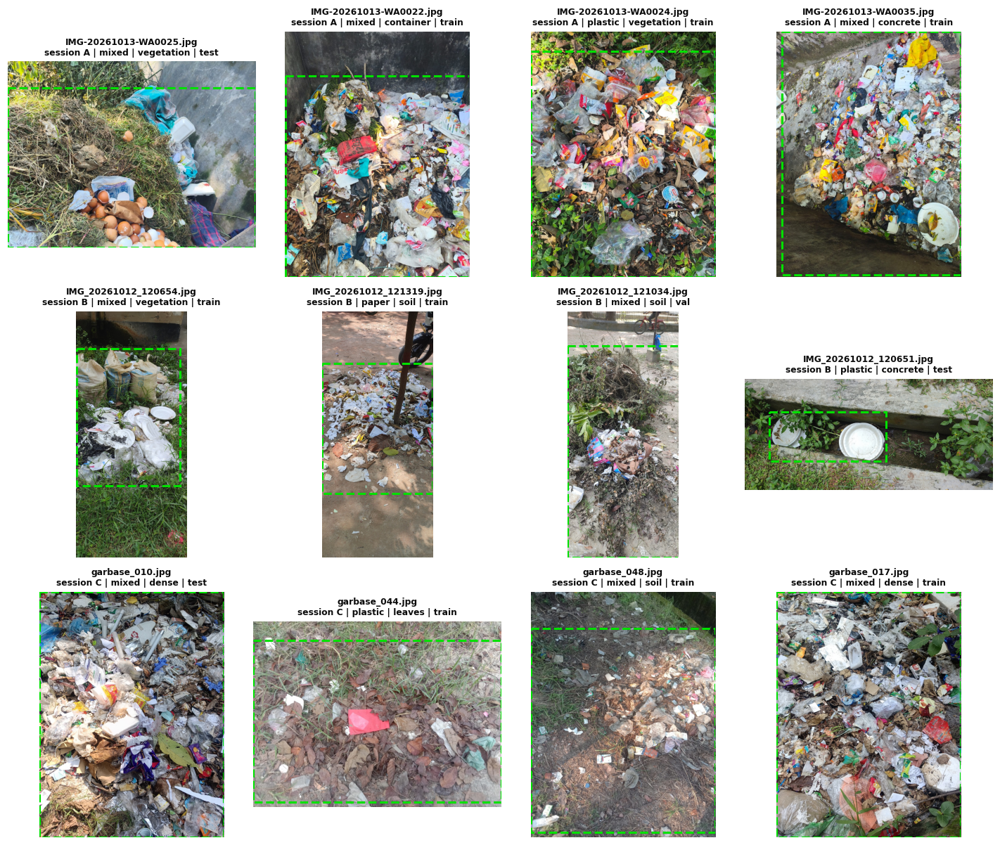

In [6]:
# figure: example annotated images (4 per session)
rng = np.random.default_rng(3)
pick = []
for s in "ABC":
    fs = meta[meta.session == s].file.tolist(); pick += list(rng.choice(fs, 4, replace=False))
fig, axes = plt.subplots(3, 4, figsize=(13, 11))
for ax, f in zip(axes.ravel(), pick):
    img = np.asarray(Image.open(GD.CACHE / f))
    gt = boxes[boxes.file == f][["x1", "y1", "x2", "y2"]].values
    r = meta.set_index("file").loc[f]
    draw_boxes(ax, img, gt=gt, title=f"{f}\nsession {r.session} | {r.composition} | {r.background} | {r.split}")
plt.tight_layout(); savefig(fig, "fig01_dataset_examples.png"); plt.show()

saved -> outputs\figures\fig02_dataset_statistics.png


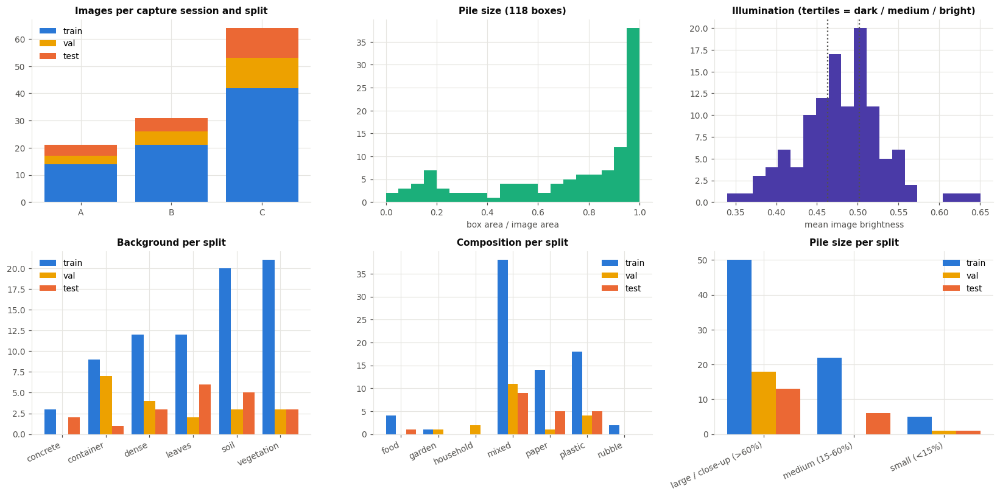

In [7]:
# figure: dataset statistics
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
ax = axes[0, 0]
ct = pd.crosstab(meta.session, meta.split)[["train", "val", "test"]]
bottom = np.zeros(3)
for sp, c in zip(["train", "val", "test"], [PALETTE[0], PALETTE[3], PALETTE[1]]):
    ax.bar(ct.index, ct[sp], bottom=bottom, color=c, label=sp); bottom += ct[sp].values
ax.set_title("Images per capture session and split"); ax.legend()
ax = axes[0, 1]
ax.hist(B.rel_area, bins=np.linspace(0, 1, 21), color=PALETTE[2]); ax.set_xlabel("box area / image area")
ax.set_title(f"Pile size ({len(B)} boxes)")
ax = axes[0, 2]
ax.hist(meta.brightness, bins=20, color=PALETTE[6]); [ax.axvline(t, color=INK2, ls=":") for t in bt]
ax.set_xlabel("mean image brightness"); ax.set_title("Illumination (tertiles = dark / medium / bright)")
for ax, col in zip(axes[1], ["background", "composition", "pile_size"]):
    t = tabs[col]; x = np.arange(len(t))
    for k, (sp, c) in enumerate(zip(["train", "val", "test"], [PALETTE[0], PALETTE[3], PALETTE[1]])):
        ax.bar(x + (k - 1) * 0.27, t[sp], 0.27, color=c, label=sp)
    ax.set_xticks(x, t.index, rotation=25, ha="right"); ax.set_title(f"{col.replace('_', ' ').capitalize()} per split"); ax.legend()
plt.tight_layout(); savefig(fig, "fig02_dataset_statistics.png"); plt.show()

## 1.3 Splitting strategy

Many photos are repeated shots of the same pile (e.g. `garbase_057/058/059`, `WA0034/36/38/40`, `IMG_…121315/16/19`).
A random split would put near-identical photos in both training and test and inflate every score. Therefore:

* all photos of one **location group** always go to the same split (0 groups cross splits, see above);
* each **capture session** is split separately (≈ 70 / 15 / 15 %), so all three sessions appear in every split;
* among the seeds that satisfy the size limits, the split whose background, composition, occlusion and session
  distributions are most similar between train and test was chosen (seed 224). Only metadata is used for this, never
  model results.

The result is 77 training, 19 validation and 20 test images. The validation set is used only for model selection
(best epoch) and to choose an optional confidence threshold; the test set is used once, for the final numbers. The
COCO-format files `annotations/coco_{all,train,val,test}.json` and `annotations/split.csv` hold the annotations and
split.

---
# 2. Data augmentation

The same bounding-box-aware pipeline (albumentations) is used for all four detectors. Boxes are transformed together
with the image. A box less than 30 % visible after a geometric change is dropped, and crops never cut a pile.

| augmentation | why it helps on campus photos |
|---|---|
| horizontal flip | piles have no left/right orientation |
| bbox-safe random crop | the same pile at different framings and positions |
| affine: scale 0.55–1.1, shift ±12 %, rotate ±8° | small, distant piles; tilted handheld shots |
| brightness/contrast ±35 %, gamma 0.7–1.4 | sun vs. shade vs. dusk |
| hue ±6, saturation ±25 | camera white balance; hue kept small so green grass stays green |
| random shadow | tree and building shadows lying across piles |
| motion / Gaussian blur | hand shake, out-of-focus shots |
| Gaussian noise | low-light sensor noise |
| JPEG compression 40–90 | WhatsApp-style re-compression (session A) |

After augmentation every image is letterboxed to 640 × 640 (longest side 640, grey padding bottom/right).

saved -> outputs\figures\fig03_augmentation.png


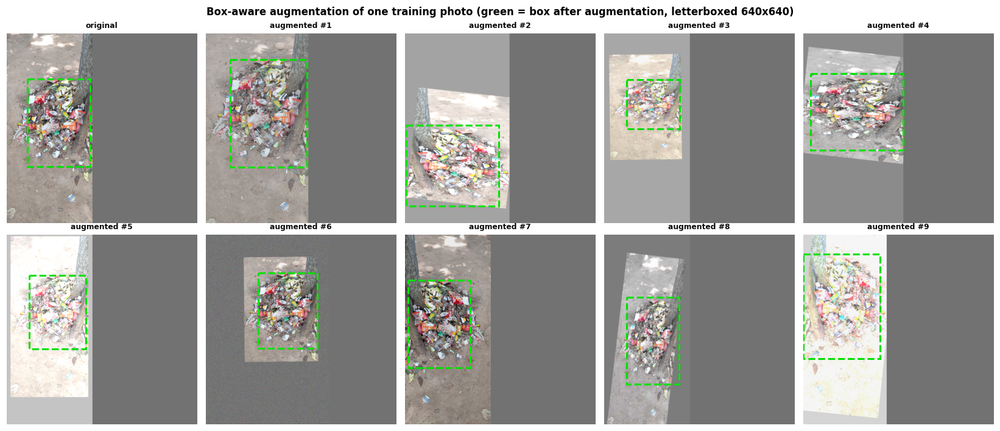

In [8]:
aug = GD.build_augment("full")
f = "IMG_20261012_121408.jpg"
img = np.asarray(Image.open(GD.CACHE / f)); bx = boxes[boxes.file == f][["x1", "y1", "x2", "y2"]].values.astype(np.float32)
fig, axes = plt.subplots(2, 5, figsize=(15, 6.6))
random.seed(1); np.random.seed(1)
for i, ax in enumerate(axes.ravel()):
    if i == 0:
        im2, b2, t = img, bx, "original"
    else:
        r = aug(image=img, bboxes=bx, labels=[0] * len(bx)); im2, b2, t = r["image"], np.array(r["bboxes"]).reshape(-1, 4), f"augmented #{i}"
    lb, (w, h) = GD.letterbox(im2)
    b2 = b2 * [w / 640, h / 640, w / 640, h / 640]
    draw_boxes(ax, lb, gt=b2, title=t)
plt.suptitle("Box-aware augmentation of one training photo (green = box after augmentation, letterboxed 640x640)", fontweight="bold")
plt.tight_layout(); savefig(fig, "fig03_augmentation.png"); plt.show()

---
# 3. Models

| | DETR | DINO | RT-DETR | Grounding DINO |
|---|---|---|---|---|
| paper | Carion et al., ECCV 2020 | Zhang et al., ICLR 2023 | Zhao et al., CVPR 2024 | Liu et al., ECCV 2024 |
| implementation | HF `facebook/detr-resnet-50` | official repo, DINO-4scale | HF `PekingU/rtdetr_r50vd` | HF `IDEA-Research/grounding-dino-tiny` (fine-tuned), `-base` (zero-shot) |
| backbone | ResNet-50 | ResNet-50 (4 scales) | ResNet-50-vd + hybrid encoder | Swin-T + BERT text encoder |
| encoder / decoder | 6 / 6 standard attention | 6 / 6 deformable attention | efficient hybrid encoder / 6 decoder | 6 / 6 deformable, cross-modal fusion |
| queries | 100 | 900 (+ denoising) | 300 (+ denoising) | 900 |
| what makes it different | first end-to-end set-prediction detector, no NMS; slow to converge | contrastive denoising, mixed query selection, look-forward-twice | real-time: efficient multi-scale encoder, IoU-aware query selection | language-conditioned: detects whatever the text prompt describes |
| COCO pretraining | 42.0 AP | 49.0 AP (12 ep) | 53.1 AP | zero-shot 48.4 AP (tiny) |

For fine-tuning, the COCO class heads are replaced by a single *piled garbage* output; all other weights start from
the pretrained checkpoint. Grounding DINO keeps its text interface: it is fine-tuned with the prompt
*"a pile of garbage."* as the only class phrase, and its BERT text encoder is frozen.

In [9]:
%%writefile gbg_models.py
"""One interface for DETR, DINO, RT-DETR and Grounding DINO.

Every wrapper takes a uint8 batch (B,3,640,640, letterboxed, padding bottom/right) plus the valid (w,h) of each image
and returns boxes normalised to the *valid* image region, so all models are evaluated identically.
  * mask-based models (DETR, DINO, Grounding DINO) get a padding mask and natively predict in valid-region coords;
  * RT-DETR has no mask and predicts in canvas coords -> converted here.
"""
import sys, math
from pathlib import Path
import torch
import torch.nn.functional as F

ROOT = Path(__file__).resolve().parent
DINO_REPO = ROOT / "third_party" / "DINO"
WEIGHTS = ROOT / "weights"
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def cxcywh_to_xyxy(b):
    cx, cy, w, h = b.unbind(-1)
    return torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1)


def xyxy_to_cxcywh(b):
    x1, y1, x2, y2 = b.unbind(-1)
    return torch.stack([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1], -1)


def valid_mask(valid, size, device):
    """True on real pixels, False on padding (B,H,W)."""
    m = torch.zeros(len(valid), size, size, dtype=torch.bool, device=device)
    for i, (w, h) in enumerate(valid):
        m[i, :h, :w] = True
    return m


class Detector:
    name = "detector"
    single_class = True                          # False for COCO-pretrained (class-agnostic evaluation)

    def __init__(self, device="cuda"):
        self.device = device

    def to_input(self, imgs):
        return imgs.to(self.device, non_blocking=True).float().div_(255)

    def parameters(self):
        return self.model.parameters()

    def n_params(self):
        return sum(p.numel() for p in self.model.parameters())

    def train(self):
        self.model.train()

    def eval(self):
        self.model.eval()

    def state_dict(self):
        return self.model.state_dict()

    def load_state_dict(self, sd):
        self.model.load_state_dict(sd)

    def param_groups(self, lr, lr_backbone, wd):
        bb, rest = [], []
        for n, p in self.model.named_parameters():
            if not p.requires_grad:
                continue
            (bb if self.is_backbone(n) else rest).append(p)
        return [{"params": rest, "lr": lr, "weight_decay": wd}, {"params": bb, "lr": lr_backbone, "weight_decay": wd}]

    @staticmethod
    def _topk(scores, boxes, k=100):
        k = min(k, scores.shape[-1])
        s, i = scores.topk(k, dim=-1)
        return [(boxes[b, i[b]].clamp(0, 1), s[b]) for b in range(len(s))]


# --------------------------------------------------------------------------------------------- DETR
class DETR(Detector):
    name = "DETR"

    def __init__(self, pretrained_coco=False, device="cuda", ckpt="facebook/detr-resnet-50"):
        super().__init__(device)
        from transformers import DetrForObjectDetection
        if pretrained_coco:
            self.model = DetrForObjectDetection.from_pretrained(ckpt)
            self.single_class = False
        else:
            self.model = DetrForObjectDetection.from_pretrained(ckpt, num_labels=1, ignore_mismatched_sizes=True)
        self.model.to(device)

    @staticmethod
    def is_backbone(n):
        return "backbone" in n

    def _forward(self, imgs, valid, labels=None):
        x = (self.to_input(imgs) - MEAN.to(self.device)) / STD.to(self.device)
        m = valid_mask(valid, x.shape[-1], self.device).long()
        return self.model(pixel_values=x, pixel_mask=m, labels=labels)

    def loss(self, imgs, boxes, valid):
        labels = [{"class_labels": torch.zeros(len(b), dtype=torch.long, device=self.device),
                   "boxes": xyxy_to_cxcywh(b.to(self.device))} for b in boxes]
        out = self._forward(imgs, valid, labels)
        return out.loss, {k: float(v) for k, v in out.loss_dict.items()}

    @torch.no_grad()
    def predict(self, imgs, valid, k=100):
        out = self._forward(imgs, valid)
        prob = out.logits.softmax(-1)[..., :-1]                   # drop the "no object" class
        scores, labels = prob.max(-1)
        res = self._topk(scores, cxcywh_to_xyxy(out.pred_boxes), k)
        if not self.single_class:
            return [(b, s, labels[i][s.argsort(descending=True)]) for i, (b, s) in enumerate(res)]
        return res


# --------------------------------------------------------------------------------------------- RT-DETR
class RTDETR(Detector):
    name = "RT-DETR"

    def __init__(self, pretrained_coco=False, device="cuda", ckpt="PekingU/rtdetr_r50vd"):
        super().__init__(device)
        from transformers import RTDetrForObjectDetection
        if pretrained_coco:
            self.model = RTDetrForObjectDetection.from_pretrained(ckpt)
            self.single_class = False
        else:
            self.model = RTDetrForObjectDetection.from_pretrained(ckpt, num_labels=1, ignore_mismatched_sizes=True)
        self.model.to(device)

    @staticmethod
    def is_backbone(n):
        return "backbone" in n

    @staticmethod
    def _scale(valid, size, device):
        return torch.tensor([[w / size, h / size, w / size, h / size] for w, h in valid], device=device)

    def loss(self, imgs, boxes, valid):
        sc = self._scale(valid, imgs.shape[-1], self.device)
        labels = [{"class_labels": torch.zeros(len(b), dtype=torch.long, device=self.device),
                   "boxes": xyxy_to_cxcywh(b.to(self.device) * sc[i])} for i, b in enumerate(boxes)]
        out = self.model(pixel_values=self.to_input(imgs), labels=labels)
        return out.loss, {k: float(v) for k, v in out.loss_dict.items()}

    @torch.no_grad()
    def predict(self, imgs, valid, k=100):
        out = self.model(pixel_values=self.to_input(imgs))
        sc = self._scale(valid, imgs.shape[-1], self.device)
        boxes = cxcywh_to_xyxy(out.pred_boxes) / sc[:, None, :]
        prob = out.logits.sigmoid()
        scores, labels = prob.max(-1)
        res = self._topk(scores, boxes, k)
        if not self.single_class:
            return [(b, s, labels[i][s.argsort(descending=True)]) for i, (b, s) in enumerate(res)]
        return res


# --------------------------------------------------------------------------------------------- DINO (official repo)
def _dino_imports():
    if str(DINO_REPO) not in sys.path:
        sys.path.insert(0, str(DINO_REPO))
    from util.slconfig import SLConfig
    from util.misc import NestedTensor
    from models.registry import MODULE_BUILD_FUNCS
    import models.dino  # noqa: F401  (registers the builder)
    return SLConfig, NestedTensor, MODULE_BUILD_FUNCS


class DINO(Detector):
    name = "DINO"

    def __init__(self, pretrained_coco=False, device="cuda", ckpt=WEIGHTS / "dino_r50_4scale_12ep.pth"):
        super().__init__(device)
        SLConfig, self.NestedTensor, REG = _dino_imports()
        args = SLConfig.fromfile(str(DINO_REPO / "config" / "DINO" / "DINO_4scale.py"))
        args.device = device
        if not pretrained_coco:
            args.num_classes, args.dn_labelbook_size = 1, 1      # one class: "piled garbage"
        else:
            self.single_class = False
        self.args = args
        self.model, self.criterion, _ = REG.get("dino")(args)
        sd = torch.load(ckpt, map_location="cpu", weights_only=False)["model"]
        if not pretrained_coco:                                    # drop the 91-class COCO heads
            own = self.model.state_dict()
            sd = {k: v for k, v in sd.items() if k in own and own[k].shape == v.shape}
        missing = self.model.load_state_dict(sd, strict=False)
        self.reinitialised = len(missing.missing_keys)
        self.model.to(device)
        self.criterion.to(device)

    @staticmethod
    def is_backbone(n):
        return "backbone.0" in n

    def _samples(self, imgs, valid):
        x = (self.to_input(imgs) - MEAN.to(self.device)) / STD.to(self.device)
        return self.NestedTensor(x, ~valid_mask(valid, x.shape[-1], self.device))

    def loss(self, imgs, boxes, valid):
        targets = [{"labels": torch.zeros(len(b), dtype=torch.long, device=self.device),
                    "boxes": xyxy_to_cxcywh(b.to(self.device))} for b in boxes]
        out = self.model(self._samples(imgs, valid), targets)
        ld = self.criterion(out, targets)
        wd = self.criterion.weight_dict
        loss = sum(ld[k] * wd[k] for k in ld if k in wd)
        return loss, {k: float(v) for k, v in ld.items() if k in ("loss_ce", "loss_bbox", "loss_giou")}

    @torch.no_grad()
    def predict(self, imgs, valid, k=100):
        out = self.model(self._samples(imgs, valid))
        prob = out["pred_logits"].sigmoid()
        scores, labels = prob.max(-1)
        res = self._topk(scores, cxcywh_to_xyxy(out["pred_boxes"]), k)
        if not self.single_class:
            return [(b, s, labels[i][s.argsort(descending=True)]) for i, (b, s) in enumerate(res)]
        return res


# --------------------------------------------------------------------------------------------- Grounding DINO
class GroundingDINO(Detector):
    name = "Grounding DINO"

    def __init__(self, ckpt="IDEA-Research/grounding-dino-tiny", prompt="a pile of garbage.", device="cuda",
                 freeze_text=True, freeze_backbone=False):
        super().__init__(device)
        from transformers import AutoProcessor, GroundingDinoForObjectDetection
        self.proc = AutoProcessor.from_pretrained(ckpt)
        self.model = GroundingDinoForObjectDetection.from_pretrained(ckpt).to(device)
        for n, p in self.model.named_parameters():
            if (freeze_text and "text_backbone" in n) or (freeze_backbone and n.startswith("model.backbone")):
                p.requires_grad_(False)
        # transformers 4.55 bug: the two-stage *encoder* classification loss is multiplied by the number of encoder
        # tokens (~8,400) instead of the number of queries, giving loss_ce_enc ~ 5e4 that swamps everything else.
        # The loss is therefore computed without the encoder term, but with the auxiliary (per-decoder-layer)
        # losses that the original Grounding DINO training uses.
        import copy
        orig = self.model.loss_function

        def _loss(*a, **kw):
            a = list(a)
            cfg = copy.copy(a[4])
            cfg.two_stage, cfg.auxiliary_loss = False, True
            a[4] = cfg
            return orig(*a, **kw)
        self.model.loss_function = _loss
        self.set_prompt(prompt)

    def set_prompt(self, prompt):
        prompt = prompt.strip().lower()
        if not prompt.endswith("."):
            prompt += "."
        self.prompt = prompt
        t = self.proc.tokenizer([prompt], return_tensors="pt")
        self.text = {k: v.to(self.device) for k, v in t.items()}
        ids = self.text["input_ids"][0]
        special = {self.proc.tokenizer.cls_token_id, self.proc.tokenizer.sep_token_id,
                   self.proc.tokenizer.convert_tokens_to_ids(".")}
        self.token_mask = torch.tensor([int(i) not in special for i in ids], device=self.device)

    @staticmethod
    def is_backbone(n):
        return n.startswith("model.backbone")

    def _forward(self, imgs, valid, labels=None):
        x = (self.to_input(imgs) - MEAN.to(self.device)) / STD.to(self.device)
        m = valid_mask(valid, x.shape[-1], self.device).long()
        B = x.shape[0]
        txt = {k: v.expand(B, -1) for k, v in self.text.items()}
        return self.model(pixel_values=x, pixel_mask=m, labels=labels, **txt)

    def loss(self, imgs, boxes, valid):
        labels = [{"class_labels": torch.zeros(len(b), dtype=torch.long, device=self.device),
                   "boxes": xyxy_to_cxcywh(b.to(self.device))} for b in boxes]
        out = self._forward(imgs, valid, labels)
        return out.loss, {k: float(v) for k, v in out.loss_dict.items() if k in ("loss_ce", "loss_bbox", "loss_giou")}

    @torch.no_grad()
    def predict(self, imgs, valid, k=100):
        out = self._forward(imgs, valid)
        L = self.token_mask.shape[0]
        prob = out.logits[..., :L].sigmoid()
        prob = prob.masked_fill(~self.token_mask[None, None, :], 0)
        scores = prob.max(-1).values                                 # best-matching prompt token per query
        return self._topk(scores, cxcywh_to_xyxy(out.pred_boxes), k)


def build(kind, **kw):
    return {"DETR": DETR, "RT-DETR": RTDETR, "DINO": DINO, "Grounding DINO": GroundingDINO}[kind](**kw)

Overwriting gbg_models.py


In [10]:
%%writefile gbg_eval.py
"""Prediction, COCO mAP, precision/recall, timing and synthetic-corruption helpers (identical for every model)."""
import time, json, io, contextlib
import numpy as np
import pandas as pd
import cv2
import torch
from PIL import Image
from gbg_data import CACHE, INPUT, letterbox


def load_cached(files):
    return {f: np.asarray(Image.open(CACHE / f).convert("RGB")) for f in files}


@torch.no_grad()
def predict_images(model, images, size=INPUT, bs=8, k=100, transform=None):
    """images: {file: HxWx3 uint8}. Returns {file: (boxes Nx4 normalised xyxy, scores N, labels or None)}."""
    model.eval()
    out, files = {}, list(images)
    for i in range(0, len(files), bs):
        chunk = files[i:i + bs]
        lbs, valid = [], []
        for f in chunk:
            img = images[f] if transform is None else transform(images[f])
            lb, v = letterbox(img, size)
            lbs.append(lb); valid.append(v)
        x = torch.from_numpy(np.stack(lbs)).permute(0, 3, 1, 2).contiguous()
        preds = model.predict(x, valid, k=k)
        for f, p in zip(chunk, preds):
            out[f] = (p[0].float().cpu().numpy(), p[1].float().cpu().numpy(), p[2].cpu().numpy() if len(p) > 2 else None)
    return out


# --------------------------------------------------------------------------------------------- COCO mAP
def coco_eval(preds, gt_boxes, meta, files=None):
    """mAP@[.5:.95], AP50, AP75 with pycocotools, in original-image pixel coordinates."""
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval
    files = list(preds) if files is None else files
    m = meta.set_index("file")
    images, anns, dets = [], [], []
    for i, f in enumerate(files, 1):
        W, H = m.loc[f, "width"], m.loc[f, "height"]
        images.append({"id": i, "width": int(W), "height": int(H)})
        for b in gt_boxes[gt_boxes.file == f].itertuples():
            w, h = (b.x2 - b.x1) * W, (b.y2 - b.y1) * H
            anns.append({"id": len(anns) + 1, "image_id": i, "category_id": 1, "bbox": [b.x1 * W, b.y1 * H, w, h],
                         "area": w * h, "iscrowd": 0})
        bx, sc, _ = preds[f]
        for b, s in zip(bx, sc):
            dets.append({"image_id": i, "category_id": 1, "score": float(s),
                         "bbox": [float(b[0] * W), float(b[1] * H), float((b[2] - b[0]) * W), float((b[3] - b[1]) * H)]})
    gt = COCO()
    gt.dataset = {"images": images, "annotations": anns, "categories": [{"id": 1, "name": "piled garbage"}]}
    with contextlib.redirect_stdout(io.StringIO()):
        gt.createIndex()
        if not dets:
            return {"AP": 0.0, "AP50": 0.0, "AP75": 0.0, "AR100": 0.0}
        dt = gt.loadRes(dets)
        E = COCOeval(gt, dt, "bbox")
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    return {"AP": float(s[0]), "AP50": float(s[1]), "AP75": float(s[2]), "AR100": float(s[8])}


# --------------------------------------------------------------------------------------------- P / R
def box_iou(a, b):
    a, b = np.asarray(a, float).reshape(-1, 4), np.asarray(b, float).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda z: (z[:, 2] - z[:, 0]) * (z[:, 3] - z[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)


def nms(boxes, scores, thr=0.5):
    order = np.argsort(-scores)
    keep = []
    while len(order):
        i = order[0]; keep.append(i)
        if len(order) == 1:
            break
        iou = box_iou(boxes[i], boxes[order[1:]])[0]
        order = order[1:][iou < thr]
    return np.array(keep, int)


def match_image(pb, ps, gb, thr_score, iou_thr=0.5):
    """Greedy one-to-one matching of kept detections (score >= thr, after NMS) to ground truth."""
    keep = ps >= thr_score
    pb, ps = pb[keep], ps[keep]
    if len(pb):
        k = nms(pb, ps, 0.5)
        pb, ps = pb[k], ps[k]
    iou = box_iou(pb, gb)
    tp, matched, best_iou = 0, set(), []
    for i in np.argsort(-ps):                       # highest-scoring detection first
        best_j, best = -1, iou_thr
        for j in range(iou.shape[1]):
            if j not in matched and iou[i, j] >= best:
                best_j, best = j, iou[i, j]
        if best_j >= 0:
            matched.add(best_j); tp += 1; best_iou.append(best)
    return {"tp": tp, "fp": len(pb) - tp, "fn": len(gb) - tp, "n_pred": len(pb),
            "max_iou": float(iou.max()) if iou.size else 0.0, "matched_iou": float(np.mean(best_iou)) if best_iou else np.nan}


def pr_at(preds, gt_boxes, thr, files=None, iou_thr=0.5):
    files = list(preds) if files is None else files
    rows = []
    for f in files:
        gb = gt_boxes[gt_boxes.file == f][["x1", "y1", "x2", "y2"]].values
        r = match_image(preds[f][0], preds[f][1], gb, thr, iou_thr)
        r["file"] = f
        rows.append(r)
    d = pd.DataFrame(rows)
    tp, fp, fn = d.tp.sum(), d.fp.sum(), d.fn.sum()
    P = tp / (tp + fp) if tp + fp else 0.0
    R = tp / (tp + fn) if tp + fn else 0.0
    return {"precision": P, "recall": R, "F1": 2 * P * R / (P + R) if P + R else 0.0,
            "TP": int(tp), "FP": int(fp), "FN": int(fn)}, d


def best_f1_threshold(preds, gt_boxes, files=None, grid=np.arange(0.05, 0.96, 0.05)):
    res = [(t, pr_at(preds, gt_boxes, t, files)[0]["F1"]) for t in grid]
    return max(res, key=lambda r: (r[1], -abs(r[0] - 0.5)))[0]


# --------------------------------------------------------------------------------------------- timing
@torch.no_grad()
def benchmark(model, images, size=INPUT, warmup=10, runs=50, batch=8):
    """End-to-end latency for one image (letterbox + normalise + network + decoding), and batched throughput."""
    model.eval()
    imgs = list(images.values())
    for i in range(warmup):
        lb, v = letterbox(imgs[i % len(imgs)], size)
        model.predict(torch.from_numpy(lb[None]).permute(0, 3, 1, 2).contiguous(), [v])
    torch.cuda.synchronize()
    lat = []
    for i in range(runs):
        t = time.perf_counter()
        lb, v = letterbox(imgs[i % len(imgs)], size)
        p = model.predict(torch.from_numpy(lb[None]).permute(0, 3, 1, 2).contiguous(), [v])
        _ = p[0][1].cpu()
        torch.cuda.synchronize()
        lat.append(time.perf_counter() - t)
    lbs = [letterbox(imgs[i % len(imgs)], size) for i in range(batch)]
    x = torch.from_numpy(np.stack([l[0] for l in lbs])).permute(0, 3, 1, 2).contiguous()
    v = [l[1] for l in lbs]
    for _ in range(3):
        model.predict(x, v)
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t = time.perf_counter()
    for _ in range(10):
        p = model.predict(x, v); _ = p[0][1].cpu()
    torch.cuda.synchronize()
    thr = 10 * batch / (time.perf_counter() - t)
    lat = np.array(lat) * 1000
    return {"latency_ms": float(lat.mean()), "latency_p95_ms": float(np.percentile(lat, 95)),
            "FPS_bs1": float(1000 / lat.mean()), f"FPS_bs{batch}": float(thr),
            "peak_mem_GB_bs8": torch.cuda.max_memory_allocated() / 2**30}


# --------------------------------------------------------------------------------------------- corruptions
def corrupt(kind, sev, seed=0):
    """Campus-condition corruptions applied to the photo before it reaches the model. sev in {1,2,3}."""
    rng = np.random.default_rng(seed)

    def f(img):
        x = img.astype(np.float32)
        if kind == "dark":                       # dusk / deep shade
            g = [1.6, 2.2, 3.0][sev - 1]
            return (255 * (x / 255) ** g * [0.8, 0.6, 0.4][sev - 1]).clip(0, 255).astype(np.uint8)
        if kind == "overexposed":                # harsh midday sun
            a = [1.5, 1.9, 2.4][sev - 1]
            return (x * a + 20).clip(0, 255).astype(np.uint8)
        if kind == "motion_blur":                # hand shake
            k = [9, 17, 27][sev - 1]
            ker = np.zeros((k, k), np.float32); ker[k // 2] = 1 / k
            return cv2.filter2D(img, -1, ker)
        if kind == "noise":                      # low-light sensor noise
            s = [12, 25, 40][sev - 1]
            return (x + rng.normal(0, s, x.shape)).clip(0, 255).astype(np.uint8)
        if kind == "haze":                       # fog / morning haze
            a = [0.35, 0.55, 0.7][sev - 1]
            return (x * (1 - a) + 215 * a).clip(0, 255).astype(np.uint8)
        if kind == "occlusion":                  # vegetation / objects covering parts of the scene
            out = img.copy(); h, w = img.shape[:2]
            n, s = [3, 5, 8][sev - 1], [0.18, 0.22, 0.26][sev - 1]
            for _ in range(n):
                bw, bh = int(s * w), int(s * h)
                x0, y0 = rng.integers(0, w - bw), rng.integers(0, h - bh)
                out[y0:y0 + bh, x0:x0 + bw] = (40, 90, 35)
            return out
        raise ValueError(kind)
    return f


CORRUPTIONS = ["dark", "overexposed", "motion_blur", "noise", "haze", "occlusion"]

Overwriting gbg_eval.py


In [11]:
%%writefile gbg_train.py
"""Fine-tuning loop shared by DETR, DINO, RT-DETR and Grounding DINO. Resumable: a killed run continues from
the last finished epoch; a finished run is skipped and its history returned."""
import json, time, math, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import gbg_data as GD
import gbg_models as GM
import gbg_eval as GE

ROOT = Path(__file__).resolve().parent
RUNS = ROOT / "outputs" / "runs"

DEFAULT = dict(epochs=60, batch=4, accum=1, lr=1e-4, lr_backbone=1e-5, weight_decay=1e-4, clip=0.1,
               lr_drop=0.75, aug="full", size=640, eval_every=2, seed=0)


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def train(name, kind, train_files, val_files, boxes, meta, cfg=None, model_kw=None, log=print):
    cfg = {**DEFAULT, **(cfg or {})}
    out = RUNS / name
    out.mkdir(parents=True, exist_ok=True)
    (out / "config.json").write_text(json.dumps({"kind": kind, **cfg, **(model_kw or {})}, indent=1, default=str))
    if (out / "done.json").exists():
        return pd.read_csv(out / "history.csv"), json.loads((out / "done.json").read_text())

    set_seed(cfg["seed"])
    model = GM.build(kind, **(model_kw or {}))
    opt = torch.optim.AdamW(model.param_groups(cfg["lr"], cfg["lr_backbone"], cfg["weight_decay"]))
    drop_at = int(round(cfg["lr_drop"] * cfg["epochs"]))
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, [drop_at], 0.1)
    hist, start, best, train_time = [], 0, (-1.0, -1.0), 0.0
    if (out / "last.pt").exists():                                      # resume
        ck = torch.load(out / "last.pt", map_location="cpu", weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        hist, start, best, train_time = ck["hist"], ck["epoch"], tuple(ck["best"]), ck["train_time"]
        log(f"[{name}] resuming at epoch {start}")

    ds = GD.GarbageDataset(train_files, boxes, augment=GD.build_augment(cfg["aug"]), size=cfg["size"])
    g = torch.Generator(); g.manual_seed(cfg["seed"] + start)
    dl = torch.utils.data.DataLoader(ds, batch_size=cfg["batch"] // cfg["accum"], shuffle=True, num_workers=0,
                                     collate_fn=GD.collate, generator=g, drop_last=True)
    val_imgs = GE.load_cached(val_files)
    torch.cuda.reset_peak_memory_stats()
    for ep in range(start, cfg["epochs"]):
        model.train()
        t0, logs, step = time.time(), [], 0
        opt.zero_grad(set_to_none=True)
        for imgs, bx, valid, _ in dl:
            loss, ld = model.loss(imgs, bx, valid)
            (loss / cfg["accum"]).backward()
            step += 1
            if step % cfg["accum"] == 0:
                torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["clip"])
                opt.step(); opt.zero_grad(set_to_none=True)
            logs.append({"loss": float(loss), **ld})
        sched.step()
        torch.cuda.synchronize()
        ep_time = time.time() - t0
        train_time += ep_time
        row = {"epoch": ep + 1, "time_s": ep_time, **pd.DataFrame(logs).mean().to_dict()}
        if (ep + 1) % cfg["eval_every"] == 0 or ep + 1 == cfg["epochs"]:
            preds = GE.predict_images(model, val_imgs, size=cfg["size"])
            m = GE.coco_eval(preds, boxes, meta, list(val_imgs))
            row.update({f"val_{k}": v for k, v in m.items()})
            key = (m["AP"], m["AP50"])
            if key > best:
                best = key
                torch.save(model.state_dict(), out / "best.pt")
                row["saved_best"] = 1
            log(f"[{name}] ep {ep + 1:3d}/{cfg['epochs']} loss {row['loss']:.3f} | val AP {m['AP']:.3f} AP50 {m['AP50']:.3f}"
                f" | {ep_time:.1f}s/ep")
        hist.append(row)
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), "hist": hist,
                    "epoch": ep + 1, "best": best, "train_time": train_time}, out / "last.pt")
        pd.DataFrame(hist).to_csv(out / "history.csv", index=False)
    done = {"train_time_s": train_time, "best_val_AP": best[0], "best_val_AP50": best[1],
            "peak_train_mem_GB": torch.cuda.max_memory_allocated() / 2**30, "params": model.n_params(),
            "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad)}
    (out / "done.json").write_text(json.dumps(done, indent=1))
    (out / "last.pt").unlink(missing_ok=True)                           # keep only best.pt to save disk
    del model, opt
    torch.cuda.empty_cache()
    return pd.DataFrame(hist), done


def load_finetuned(name, kind, model_kw=None):
    m = GM.build(kind, **(model_kw or {}))
    m.load_state_dict(torch.load(RUNS / name / "best.pt", map_location="cpu", weights_only=False))
    m.eval()
    return m

Overwriting gbg_train.py


In [12]:
import gbg_models as GM, gbg_eval as GE, gbg_train as GT

---
# 4. Original pretrained models (before fine-tuning)

COCO has no garbage class. To still measure what the original checkpoints can do, their detections are evaluated
**class-agnostically**: every box they predict, whatever its COCO label, counts as a *piled garbage* prediction. This
asks whether the pretrained models localise garbage piles at all. Grounding DINO is evaluated zero-shot with the three
prompts from the assignment. Because none of these models has seen the RU photos, they are evaluated on all 116 images
as well as on the 20 test images.

In [13]:
TEST_IMGS = GE.load_cached(TEST)
ALL_IMGS = GE.load_cached(ALL)

def cached(name, fn):
    p = PRED / f"{name}.pkl"
    if p.exists():
        return pickle.loads(p.read_bytes())
    r = fn(); p.write_bytes(pickle.dumps(r)); return r

def evaluate(preds, files, thr=0.3):
    m = GE.coco_eval({f: preds[f] for f in files}, boxes, meta, files)
    pr, _ = GE.pr_at({f: preds[f] for f in files}, boxes, thr, files)
    return {**m, **pr}

pre_rows, PRE = [], {}
from transformers import DetrConfig, RTDetrConfig
coco_names = DetrConfig.from_pretrained("facebook/detr-resnet-50").id2label
for kind in ["DETR", "DINO", "RT-DETR"]:
    def run(kind=kind):
        m = GM.build(kind, pretrained_coco=True)
        p = GE.predict_images(m, ALL_IMGS); del m; torch.cuda.empty_cache(); return p
    PRE[kind] = cached(f"pretrained_{kind}", run)
for tag, ck in [("GD-tiny", "IDEA-Research/grounding-dino-tiny"), ("GD-base", "IDEA-Research/grounding-dino-base")]:
    for prompt in ["a pile of garbage", "a pile of plastic waste", "garbage dumped beside a campus road"]:
        def run(ck=ck, prompt=prompt):
            m = GM.GroundingDINO(ckpt=ck, prompt=prompt); p = GE.predict_images(m, ALL_IMGS); del m; torch.cuda.empty_cache(); return p
        PRE[f"{tag} | {prompt}"] = cached(f"zeroshot_{tag}_{prompt.replace(' ', '_')}", run)
for k, p in PRE.items():
    for subset, files in [("test", TEST), ("all 116", ALL)]:
        pre_rows.append({"model": k, "images": subset, **evaluate(p, files)})
PRE_DF = pd.DataFrame(pre_rows).set_index(["model", "images"]).round(3)
display(PRE_DF[["AP", "AP50", "AP75", "precision", "recall", "F1"]]); PRE_DF.to_csv(RES / "pretrained_and_zeroshot.csv")

AP   AP50   AP75  \
model                                         images                         
DETR                                          test     0.010  0.015  0.010   
                                              all 116  0.003  0.006  0.002   
DINO                                          test     0.013  0.019  0.013   
                                              all 116  0.005  0.008  0.005   
RT-DETR                                       test     0.013  0.021  0.010   
                                              all 116  0.014  0.018  0.013   
GD-tiny | a pile of garbage                   test     0.583  0.716  0.716   
                                              all 116  0.520  0.645  0.583   
GD-tiny | a pile of plastic waste             test     0.492  0.563  0.563   
                                              all 116  0.442  0.544  0.501   
GD-tiny | garbage dumped beside a campus road test     0.503  0.618  0.618   
                                              all 116  0.520  0.672  0.575   
GD-base | a pile of garbage                   test     0.560  0.652  0.652   
                                              all 116  0.513  0.629  0.563   
GD-base | a pile of plastic waste             test     0.482  0.561  0.561   
                                              all 116  0.472  0.582  0.521   
GD-base | garbage dumped beside a campus road test     0.409  0.479  0.479   
                                              all 116  0.539  0.677  0.574   

                                                       precision  recall  \
model                                         images                       
DETR                                          test         0.026   0.050   
                                              all 116      0.011   0.025   
DINO                                          test         0.056   0.050   
                                              all 116      0.023   0.017   
RT-DETR                                       test         0.037   0.100   
                                              all 116      0.053   0.119   
GD-tiny | a pile of garbage                   test         0.760   0.950   
                                              all 116      0.738   0.881   
GD-tiny | a pile of plastic waste             test         0.410   0.800   
                                              all 116      0.490   0.814   
GD-tiny | garbage dumped beside a campus road test         0.415   0.850   
                                              all 116      0.463   0.847   
GD-base | a pile of garbage                   test         0.600   0.900   
                                              all 116      0.715   0.873   
GD-base | a pile of plastic waste             test         0.444   0.800   
                                              all 116      0.555   0.814   
GD-base | garbage dumped beside a campus road test         0.378   0.700   
                                              all 116      0.483   0.839   

                                                          F1  
model                                         images          
DETR                                          test     0.034  
                                              all 116  0.015  
DINO                                          test     0.053  
                                              all 116  0.020  
RT-DETR                                       test     0.054  
                                              all 116  0.073  
GD-tiny | a pile of garbage                   test     0.844  
                                              all 116  0.803  
GD-tiny | a pile of plastic waste             test     0.542  
                                              all 116  0.611  
GD-tiny | garbage dumped beside a campus road test     0.557  
                                              all 116  0.599  
GD-base | a pile of garbage                   test     0.720  
                               

detections (score>=0.5, all 116 images)
model   label                                              
DETR    teddy bear                                       35
        bottle                                           30
        banana                                           15
        bowl                                             15
        apple                                            13
        broccoli                                         12
DINO    motorcycle                                        4
        banana                                            2
        bicycle                                           2
        car                                               2
        person                                            2
        bowl                                              1
RT-DETR bowl                                             12
        banana                                            8
        bottle                                            8
        cup                                               8
        toilet                                            8
        person                                            5

saved -> outputs\figures\fig04_pretrained_detections.png


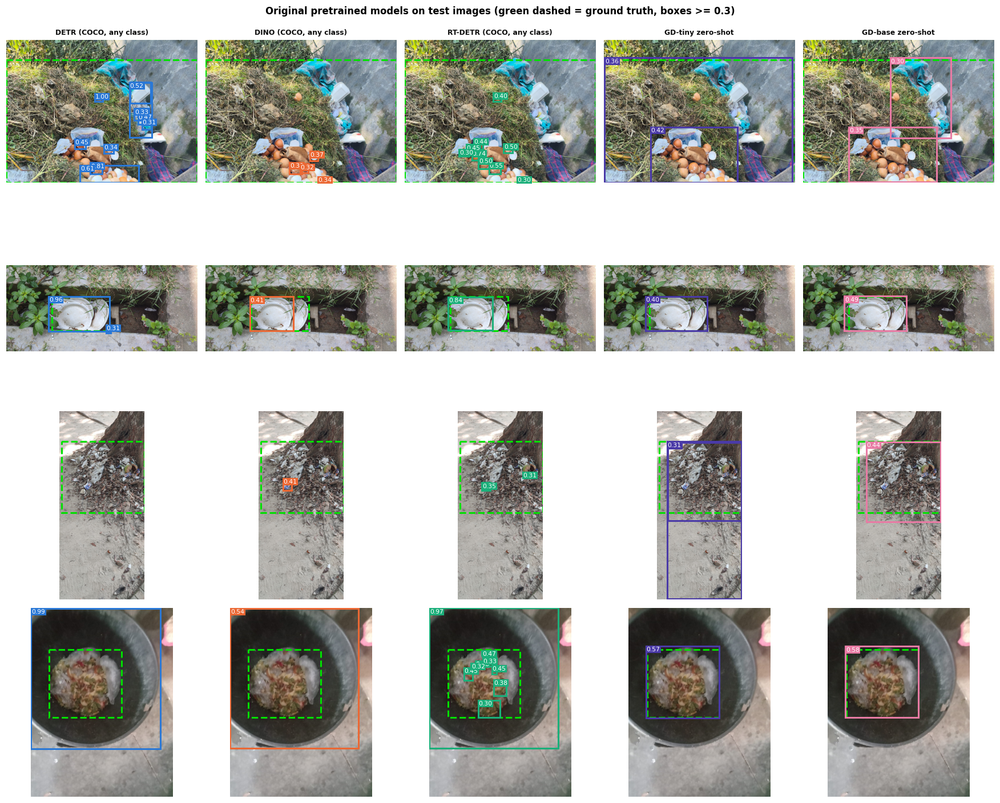

In [14]:
# which COCO classes do the original detectors fire on when they look at garbage?
rows = []
for kind in ["DETR", "DINO", "RT-DETR"]:
    names = coco_names if kind != "RT-DETR" else RTDetrConfig.from_pretrained("PekingU/rtdetr_r50vd").id2label
    for f, (bx, sc, lab) in PRE[kind].items():
        for s, l in zip(sc, lab):
            if s >= 0.5:
                rows.append({"model": kind, "label": names.get(int(l), str(int(l)))})
lab = pd.DataFrame(rows).groupby("model").label.value_counts().groupby(level=0).head(6).rename("detections (score>=0.5, all 116 images)")
display(lab.to_frame()); lab.to_csv(RES / "pretrained_coco_labels.csv")

fig, axes = plt.subplots(4, 5, figsize=(16, 13))
show = TEST[::4][:4]
cols = [("DETR", "DETR (COCO, any class)"), ("DINO", "DINO (COCO, any class)"), ("RT-DETR", "RT-DETR (COCO, any class)"),
        ("GD-tiny | a pile of garbage", "GD-tiny zero-shot"), ("GD-base | a pile of garbage", "GD-base zero-shot")]
for r, f in enumerate(show):
    gt = boxes[boxes.file == f][["x1", "y1", "x2", "y2"]].values
    for c, (k, t) in enumerate(cols):
        draw_boxes(axes[r, c], TEST_IMGS[f], gt=gt, pred=PRE[k][f], colour=PALETTE[[0, 1, 2, 6, 4][c]], thr=0.3,
                   title=t if r == 0 else None)
plt.suptitle("Original pretrained models on test images (green dashed = ground truth, boxes >= 0.3)", fontweight="bold")
plt.tight_layout(); savefig(fig, "fig04_pretrained_detections.png"); plt.show()

---
# 5. Fine-tuning

All four detectors use the same recipe (the defaults of the original DETR-family papers). The only exception is
Grounding DINO's micro-batch: 2 images with 2 accumulation steps, so it fits in 16 GB with the same effective batch.

| setting | value |
|---|---|
| epochs | 60 (learning rate × 0.1 after epoch 45) |
| batch | 4 (Grounding DINO: 2 × 2 accumulation) |
| optimiser | AdamW, lr 1e-4, backbone lr 1e-5, weight decay 1e-4, gradient clipping 0.1 |
| input | 640 × 640 letterbox, augmentation of §2 |
| model selection | best validation mAP@0.5:0.95 (checked every 2 epochs) |
| seeds | 0, 1, 2 (results reported as mean ± std; seed 0 weights are kept and used for figures) |
| hardware | 1 × RTX 5070 Ti 16 GB, fp32 with TF32 matmuls |

Grounding DINO in `transformers` 4.55 has a bug in the encoder loss term: it is multiplied by about 8,400 encoder
tokens and comes out near 5 × 10⁴. That term is left out; the decoder and per-layer auxiliary losses are used.

In [15]:
TAG = {"DETR": "detr", "DINO": "dino", "RT-DETR": "rtdetr", "Grounding DINO": "gdino"}
KCFG = {"DETR": {}, "DINO": {}, "RT-DETR": {}, "Grounding DINO": {"accum": 2}}
SEEDS = [0, 1, 2]
HIST, DONE = {}, {}
t0 = time.time()
for kind in MODELS:
    for s in SEEDS:
        name = f"{TAG[kind]}_s{s}"
        HIST[name], DONE[name] = GT.train(name, kind, TRAIN, VAL, boxes, meta, {**KCFG[kind], "seed": s})
print(f"training cell finished in {(time.time() - t0) / 60:.1f} min")
cost = pd.DataFrame([{"model": k, "seed": s, "train time (min)": DONE[f"{TAG[k]}_s{s}"]["train_time_s"] / 60,
                      "peak train memory (GB)": DONE[f"{TAG[k]}_s{s}"]["peak_train_mem_GB"],
                      "params (M)": DONE[f"{TAG[k]}_s{s}"]["params"] / 1e6,
                      "trainable (M)": DONE[f"{TAG[k]}_s{s}"]["trainable_params"] / 1e6,
                      "best val AP": DONE[f"{TAG[k]}_s{s}"]["best_val_AP"]} for k in MODELS for s in SEEDS])
COST = cost.groupby("model").agg(["mean", "std"]).drop(columns=[("seed", "mean"), ("seed", "std")]).round(2).loc[MODELS]
display(COST); COST.to_csv(RES / "training_cost.csv")

training cell finished in 0.0 min


train time (min)       peak train memory (GB)       params (M)  \
                           mean   std                   mean   std       mean   
model                                                                           
DETR                       2.89  0.02                   2.09  0.27      41.50   
DINO                       9.73  0.05                  10.97  0.04      46.82   
RT-DETR                    5.31  0.05                   4.40  0.03      42.73   
Grounding DINO            12.88  0.19                   9.94  0.38     172.25   

                    trainable (M)      best val AP        
                std          mean  std        mean   std  
model                                                     
DETR            0.0         41.28  0.0        0.88  0.01  
DINO            0.0         46.60  0.0        0.90  0.01  
RT-DETR         0.0         42.73  0.0        0.90  0.01  
Grounding DINO  0.0         63.36  0.0        0.92  0.01

saved -> outputs\figures\fig05_training_curves.png


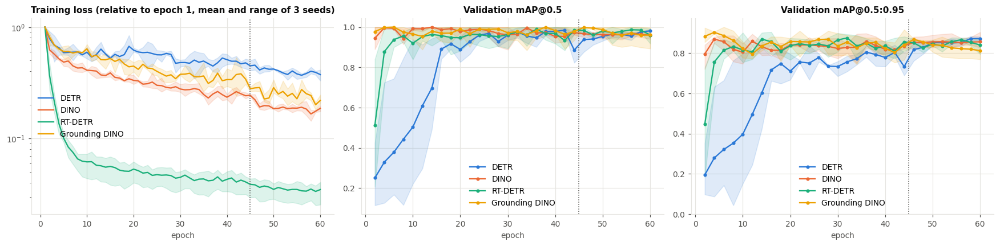

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for kind in MODELS:
    hs = [HIST[f"{TAG[kind]}_s{s}"] for s in SEEDS]
    L = np.stack([h.loss.values / h.loss.values[0] for h in hs])
    axes[0].plot(hs[0].epoch, L.mean(0), color=COL[kind], label=kind)
    axes[0].fill_between(hs[0].epoch, L.min(0), L.max(0), color=COL[kind], alpha=0.15)
    for ax, key in [(axes[1], "val_AP50"), (axes[2], "val_AP")]:
        V = np.stack([h.dropna(subset=[key])[key].values for h in hs]); e = hs[0].dropna(subset=[key]).epoch
        ax.plot(e, V.mean(0), "-o", ms=3, color=COL[kind], label=kind); ax.fill_between(e, V.min(0), V.max(0), color=COL[kind], alpha=0.15)
axes[0].set_yscale("log"); axes[0].set_title("Training loss (relative to epoch 1, mean and range of 3 seeds)")
axes[1].set_title("Validation mAP@0.5"); axes[2].set_title("Validation mAP@0.5:0.95")
for ax in axes:
    ax.set_xlabel("epoch"); ax.axvline(45, color=INK2, ls=":", lw=1); ax.legend()
plt.tight_layout(); savefig(fig, "fig05_training_curves.png"); plt.show()

---
# 6. Performance on the held-out test set

Every model is evaluated on the same 20 test images, with:

* **mAP@0.5 and mAP@0.5:0.95**: COCO protocol (pycocotools), threshold-free, top-100 boxes per image;
* **precision, recall and F1** at a fixed confidence **0.3** after NMS (IoU 0.5), with detections matched one-to-one at IoU ≥ 0.5;
* **latency**: one image end to end (letterbox, normalisation, network, decoding), batch 1, mean of 50 runs after 10 warm-up runs; **FPS** = 1 / latency, plus batched throughput (batch 8);
* parameters, GFLOPs (one 640 × 640 image) and peak inference memory.

The same hardware, input size, threshold and post-processing are used for every model.

In [17]:
def finetuned_preds(name, kind, files_imgs, tag, model_kw=None, size=640):
    def run():
        m = GT.load_finetuned(name, kind, model_kw); p = GE.predict_images(m, files_imgs, size=size); del m; torch.cuda.empty_cache(); return p
    return cached(f"{name}_{tag}", run)

VAL_IMGS = GE.load_cached(VAL)
FT, FTV = {}, {}
for kind in MODELS:
    for s in SEEDS:
        n = f"{TAG[kind]}_s{s}"
        FT[n] = finetuned_preds(n, kind, TEST_IMGS, "test")
        FTV[n] = finetuned_preds(n, kind, VAL_IMGS, "val")
rows = []
for kind in MODELS:
    for s in SEEDS:
        n = f"{TAG[kind]}_s{s}"
        r = evaluate(FT[n], TEST, 0.3)
        tb = GE.best_f1_threshold(FTV[n], boxes, VAL)
        r2, _ = GE.pr_at(FT[n], boxes, tb, TEST)
        rows.append({"model": kind, "seed": s, **r, "val-chosen thr": tb, "P@val thr": r2["precision"], "R@val thr": r2["recall"]})
SEED_DF = pd.DataFrame(rows); SEED_DF.to_csv(RES / "test_metrics_per_seed.csv", index=False)
for kind in MODELS:                       # seed-0 weights are the deliverable; seeds 1-2 are only needed for their cached predictions
    for s in SEEDS[1:]:
        (GT.RUNS / f"{TAG[kind]}_s{s}" / "best.pt").unlink(missing_ok=True)
agg = SEED_DF.groupby("model")[["AP50", "AP", "AP75", "precision", "recall", "F1", "P@val thr", "R@val thr"]].agg(["mean", "std"]).loc[MODELS]
display(agg.round(3)); agg.to_csv(RES / "test_metrics_mean_std.csv")

AP50            AP          AP75        precision         \
                 mean    std   mean    std   mean    std      mean    std   
model                                                                       
DETR            0.860  0.005  0.650  0.034  0.748  0.078     0.741  0.056   
DINO            0.891  0.037  0.684  0.045  0.778  0.015     0.873  0.027   
RT-DETR         0.853  0.067  0.661  0.063  0.771  0.062     0.792  0.056   
Grounding DINO  0.965  0.028  0.783  0.021  0.901  0.020     0.950  0.050   

               recall            F1        P@val thr        R@val thr         
                 mean    std   mean    std      mean    std      mean    std  
model                                                                         
DETR            0.900  0.050  0.812  0.054     0.788  0.026     0.867  0.029  
DINO            0.917  0.029  0.894  0.028     0.882  0.049     0.833  0.076  
RT-DETR         0.933  0.029  0.856  0.019     0.853  0.028     0.850  0.100  
Grounding DINO  0.933  0.029  0.941  0.038     0.981  0.032     0.883  0.029

In [18]:
# speed, size and compute (seed-0 weights; identical architecture for every seed)
from torch.utils.flop_counter import FlopCounterMode
SPEED = {}
def speed_of(m, size=640):
    lb, v = GD.letterbox(next(iter(TEST_IMGS.values())), size)
    x = torch.from_numpy(lb[None]).permute(0, 3, 1, 2).contiguous()
    with FlopCounterMode(display=False) as fc:
        m.predict(x, [v])
    return {**GE.benchmark(m, TEST_IMGS, size=size), "GFLOPs": fc.get_total_flops() / 1e9, "params (M)": m.n_params() / 1e6}
for kind in MODELS:
    m = GT.load_finetuned(f"{TAG[kind]}_s0", kind); SPEED[kind] = speed_of(m); del m; torch.cuda.empty_cache()
m = GM.GroundingDINO(ckpt="IDEA-Research/grounding-dino-base"); SPEED["GD-base zero-shot"] = speed_of(m); del m; torch.cuda.empty_cache()
SPEED_DF = pd.DataFrame(SPEED).T.round(2); display(SPEED_DF); SPEED_DF.to_csv(RES / "speed.csv")

,latency_ms,latency_p95_ms,FPS_bs1,FPS_bs8,peak_mem_GB_bs8,GFLOPs,params (M)
DETR,24.17,31.45,41.38,133.20,1.06,77.12,41.50
DINO,67.06,72.50,14.91,27.14,4.25,236.89,46.82
RT-DETR,29.76,46.13,33.60,98.20,1.10,137.43,42.73
Grounding DINO,81.79,86.51,12.23,22.37,4.91,328.42,172.25
GD-base zero-shot,95.03,101.32,10.52,16.47,5.00,550.46,232.31


,mAP@0.5,mAP@0.5:0.95,precision@0.3,recall@0.3,latency (ms),FPS (bs 1),FPS (bs 8),GFLOPs,params (M)
DETR,0.860 ± 0.005,0.650 ± 0.034,0.741 ± 0.056,0.900 ± 0.050,24.2,41.4,133.2,77,41.5
DINO,0.891 ± 0.037,0.684 ± 0.045,0.873 ± 0.027,0.917 ± 0.029,67.1,14.9,27.1,237,46.8
RT-DETR,0.853 ± 0.067,0.661 ± 0.063,0.792 ± 0.056,0.933 ± 0.029,29.8,33.6,98.2,137,42.7
Grounding DINO,0.965 ± 0.028,0.783 ± 0.021,0.950 ± 0.050,0.933 ± 0.029,81.8,12.2,22.4,328,172.2


saved -> outputs\figures\fig06_test_comparison.png


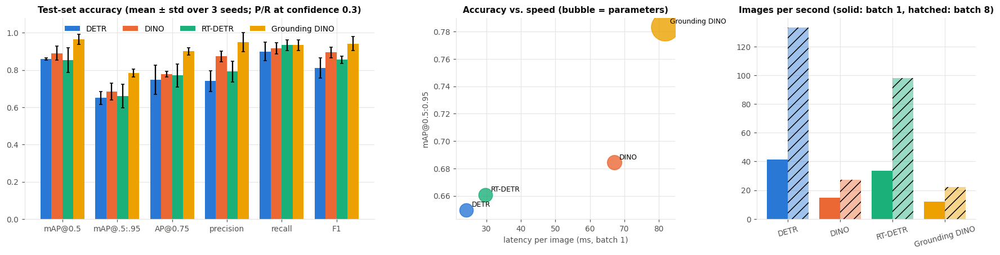

In [19]:
MAIN_TAB = pd.DataFrame({k: {"mAP@0.5": f"{agg.loc[k, ('AP50', 'mean')]:.3f} ± {agg.loc[k, ('AP50', 'std')]:.3f}",
                            "mAP@0.5:0.95": f"{agg.loc[k, ('AP', 'mean')]:.3f} ± {agg.loc[k, ('AP', 'std')]:.3f}",
                            "precision@0.3": f"{agg.loc[k, ('precision', 'mean')]:.3f} ± {agg.loc[k, ('precision', 'std')]:.3f}",
                            "recall@0.3": f"{agg.loc[k, ('recall', 'mean')]:.3f} ± {agg.loc[k, ('recall', 'std')]:.3f}",
                            "latency (ms)": f"{SPEED[k]['latency_ms']:.1f}", "FPS (bs 1)": f"{SPEED[k]['FPS_bs1']:.1f}",
                            "FPS (bs 8)": f"{SPEED[k]['FPS_bs8']:.1f}", "GFLOPs": f"{SPEED[k]['GFLOPs']:.0f}",
                            "params (M)": f"{SPEED[k]['params (M)']:.1f}"} for k in MODELS}).T
display(MAIN_TAB); MAIN_TAB.to_csv(RES / "main_comparison.csv")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1.6, 1, 1]})
ax = axes[0]; mets = ["AP50", "AP", "AP75", "precision", "recall", "F1"]; x = np.arange(len(mets))
for i, k in enumerate(MODELS):
    ax.bar(x + (i - 1.5) * 0.2, [agg.loc[k, (m, "mean")] for m in mets], 0.2, yerr=[agg.loc[k, (m, "std")] for m in mets],
           color=COL[k], label=k, capsize=2)
ax.set_xticks(x, ["mAP@0.5", "mAP@.5:.95", "AP@0.75", "precision", "recall", "F1"]); ax.set_ylim(0, 1.08); ax.legend(ncol=4, loc="upper center")
ax.set_title("Test-set accuracy (mean ± std over 3 seeds; P/R at confidence 0.3)")
ax = axes[1]
for k in MODELS:
    ax.scatter(SPEED[k]["latency_ms"], agg.loc[k, ("AP", "mean")], s=SPEED[k]["params (M)"] * 6, color=COL[k], alpha=0.8, label=k)
    ax.annotate(k, (SPEED[k]["latency_ms"], agg.loc[k, ("AP", "mean")]), xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("latency per image (ms, batch 1)"); ax.set_ylabel("mAP@0.5:0.95"); ax.set_title("Accuracy vs. speed (bubble = parameters)")
ax = axes[2]
for i, k in enumerate(MODELS):
    ax.bar(i - 0.2, SPEED[k]["FPS_bs1"], 0.4, color=COL[k]); ax.bar(i + 0.2, SPEED[k]["FPS_bs8"], 0.4, color=COL[k], alpha=0.45, hatch="//")
ax.set_xticks(range(4), MODELS, rotation=15); ax.set_title("Images per second (solid: batch 1, hatched: batch 8)")
plt.tight_layout(); savefig(fig, "fig06_test_comparison.png"); plt.show()

saved -> outputs\figures\fig07_pr_curves.png


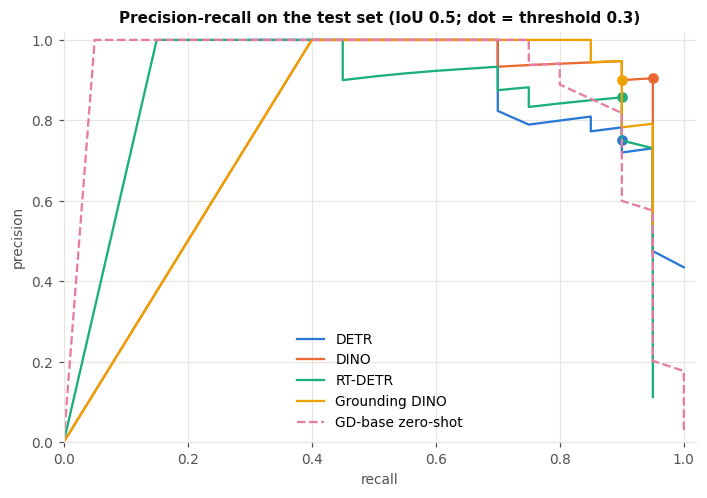

In [20]:
# precision-recall curves on the test set (seed 0), sweeping the confidence threshold
fig, ax = plt.subplots(figsize=(6.5, 4.6))
for k in MODELS:
    pts = [GE.pr_at(FT[f"{TAG[k]}_s0"], boxes, t, TEST)[0] for t in np.linspace(0.02, 0.98, 49)]
    ax.plot([p["recall"] for p in pts], [p["precision"] for p in pts], "-", color=COL[k], label=k)
    p3 = GE.pr_at(FT[f"{TAG[k]}_s0"], boxes, 0.3, TEST)[0]; ax.plot(p3["recall"], p3["precision"], "o", color=COL[k])
p = PRE["GD-base | a pile of garbage"]
pts = [GE.pr_at(p, boxes, t, TEST)[0] for t in np.linspace(0.02, 0.98, 49)]
ax.plot([q["recall"] for q in pts], [q["precision"] for q in pts], "--", color=COL["GD-base zero-shot"], label="GD-base zero-shot")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02); ax.legend()
ax.set_title("Precision-recall on the test set (IoU 0.5; dot = threshold 0.3)")
plt.tight_layout(); savefig(fig, "fig07_pr_curves.png"); plt.show()

---
# 7. Original pretrained vs. fine-tuned models

AP50     AP  precision  \
model          stage                                                       
DETR           original (COCO / zero-shot)       0.015  0.010      0.026   
               fine-tuned (mean of 3 seeds)      0.860  0.650      0.741   
DINO           original (COCO / zero-shot)       0.019  0.013      0.056   
               fine-tuned (mean of 3 seeds)      0.891  0.684      0.873   
RT-DETR        original (COCO / zero-shot)       0.021  0.013      0.037   
               fine-tuned (mean of 3 seeds)      0.853  0.661      0.792   
Grounding DINO original (COCO / zero-shot)       0.716  0.583      0.760   
               fine-tuned (mean of 3 seeds)      0.965  0.783      0.950   
               GD-base zero-shot (larger model)  0.652  0.560      0.600   

                                                 recall  
model          stage                                     
DETR           original (COCO / zero-shot)        0.050  
               fine-tuned (mean of 3 seeds)       0.900  
DINO           original (COCO / zero-shot)        0.050  
               fine-tuned (mean of 3 seeds)       0.917  
RT-DETR        original (COCO / zero-shot)        0.100  
               fine-tuned (mean of 3 seeds)       0.933  
Grounding DINO original (COCO / zero-shot)        0.950  
               fine-tuned (mean of 3 seeds)       0.933  
               GD-base zero-shot (larger model)   0.900

saved ->

 outputs\figures\fig08_original_vs_finetuned.png


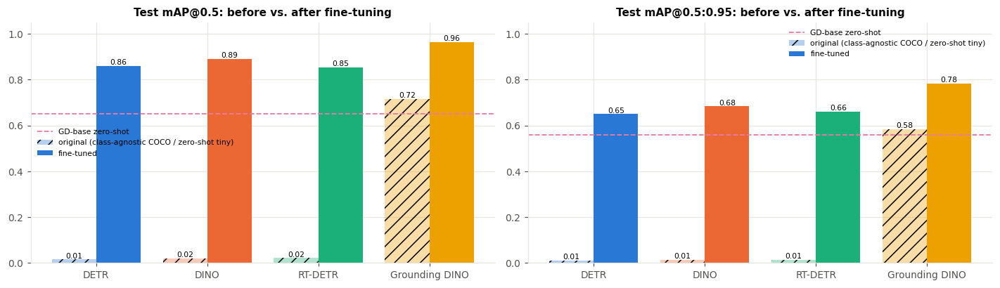

In [21]:
rows = []
for kind, pre in [("DETR", "DETR"), ("DINO", "DINO"), ("RT-DETR", "RT-DETR"), ("Grounding DINO", "GD-tiny | a pile of garbage")]:
    o = PRE_DF.loc[(pre, "test")]
    rows.append({"model": kind, "stage": "original (COCO / zero-shot)", "AP50": o.AP50, "AP": o.AP, "precision": o.precision, "recall": o.recall})
    rows.append({"model": kind, "stage": "fine-tuned (mean of 3 seeds)", "AP50": agg.loc[kind, ("AP50", "mean")],
                 "AP": agg.loc[kind, ("AP", "mean")], "precision": agg.loc[kind, ("precision", "mean")], "recall": agg.loc[kind, ("recall", "mean")]})
o = PRE_DF.loc[("GD-base | a pile of garbage", "test")]
rows.append({"model": "Grounding DINO", "stage": "GD-base zero-shot (larger model)", "AP50": o.AP50, "AP": o.AP, "precision": o.precision, "recall": o.recall})
BA = pd.DataFrame(rows).set_index(["model", "stage"]).round(3); display(BA); BA.to_csv(RES / "original_vs_finetuned.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, met, t in [(axes[0], "AP50", "mAP@0.5"), (axes[1], "AP", "mAP@0.5:0.95")]:
    x = np.arange(4)
    ax.bar(x - 0.2, [BA.loc[(k, "original (COCO / zero-shot)"), met] for k in MODELS], 0.4, color=[COL[k] for k in MODELS], alpha=0.35,
           hatch="//", label="original (class-agnostic COCO / zero-shot tiny)")
    ax.bar(x + 0.2, [BA.loc[(k, "fine-tuned (mean of 3 seeds)"), met] for k in MODELS], 0.4, color=[COL[k] for k in MODELS], label="fine-tuned")
    ax.axhline(BA.loc[("Grounding DINO", "GD-base zero-shot (larger model)"), met], color=COL["GD-base zero-shot"], ls="--", lw=1.2, label="GD-base zero-shot")
    ax.set_xticks(x, MODELS); ax.set_ylim(0, 1.05); ax.set_title(f"Test {t}: before vs. after fine-tuning"); ax.legend(fontsize=7)
    for c in ax.containers[:2]:
        ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout(); savefig(fig, "fig08_original_vs_finetuned.png"); plt.show()

---
# 8. Training configurations: accuracy vs. efficiency

Six additional runs (seed 0) change one setting at a time:

* **RT-DETR without augmentation**: how much the §2 pipeline contributes;
* **RT-DETR at 480 and 800 px input**: resolution vs. accuracy vs. speed;
* **DETR for 150 epochs**: DETR is known to converge slowly;
* **DINO for 12 epochs**: does DINO's denoising training reach its accuracy faster?
* **Grounding DINO with a frozen Swin backbone**: memory and time saved vs. accuracy lost.

,AP50,AP,precision,recall,latency (ms),train time (min),peak train mem (GB),trainable (M)
configuration,,,,,,,,
"RT-DETR, default (60 ep, 640 px, aug)",0.854,0.665,0.857,0.90,29.760,5.364,4.428,42.729
"RT-DETR, no augmentation",0.876,0.678,0.810,0.85,27.691,4.221,3.888,42.729
"RT-DETR, 480 px",0.868,0.670,0.720,0.90,31.166,4.823,3.476,42.729
"RT-DETR, 800 px",0.913,0.692,0.905,0.95,27.496,6.426,6.275,42.729
"DETR, default (60 ep, 640 px, aug)",0.855,0.618,0.750,0.90,24.168,2.899,1.780,41.279
"DETR, 150 epochs",0.896,0.666,0.643,0.90,23.673,7.879,2.582,41.279
"DINO, default (60 ep, 640 px, aug)",0.932,0.732,0.905,0.95,67.057,9.711,10.922,46.601
"DINO, 12 epochs",0.903,0.670,0.857,0.90,58.731,1.913,10.451,46.601
"Grounding DINO, default (60 ep, 640 px, aug)",0.935,0.769,0.900,0.90,81.786,12.844,9.502,63.357


saved -> outputs\figures\fig09_training_configurations.png


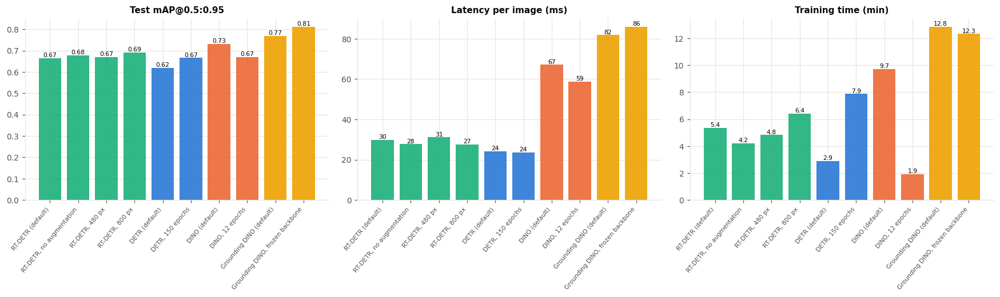

In [22]:
CFGS = [("rtdetr_noaug_s0", "RT-DETR", {"aug": "none"}, None, 640, "RT-DETR, no augmentation"),
        ("rtdetr_480_s0", "RT-DETR", {"size": 480}, None, 480, "RT-DETR, 480 px"),
        ("rtdetr_800_s0", "RT-DETR", {"size": 800}, None, 800, "RT-DETR, 800 px"),
        ("detr_150ep_s0", "DETR", {"epochs": 150}, None, 640, "DETR, 150 epochs"),
        ("dino_12ep_s0", "DINO", {"epochs": 12}, None, 640, "DINO, 12 epochs"),
        ("gdino_frozenbb_s0", "Grounding DINO", {"accum": 2}, {"freeze_backbone": True}, 640, "Grounding DINO, frozen backbone")]
rows = []
for name, kind, cfg, mkw, size, label in CFGS:
    h, d = GT.train(name, kind, TRAIN, VAL, boxes, meta, {**KCFG[kind], **cfg, "seed": 0}, model_kw=mkw)
    p = finetuned_preds(name, kind, TEST_IMGS, "test", mkw, size)
    sp = cached(f"{name}_speed", lambda: (lambda m: (GE.benchmark(m, TEST_IMGS, size=size), m.n_params()))(GT.load_finetuned(name, kind, mkw)))
    torch.cuda.empty_cache()
    rows.append({"configuration": label, **evaluate(p, TEST), "latency (ms)": sp[0]["latency_ms"], "train time (min)": d["train_time_s"] / 60,
                 "peak train mem (GB)": d["peak_train_mem_GB"], "trainable (M)": d["trainable_params"] / 1e6})
for kind in MODELS:                                                   # the reference (default) seed-0 runs
    d = DONE[f"{TAG[kind]}_s0"]
    rows.append({"configuration": f"{kind}, default (60 ep, 640 px, aug)", **evaluate(FT[f"{TAG[kind]}_s0"], TEST),
                 "latency (ms)": SPEED[kind]["latency_ms"], "train time (min)": d["train_time_s"] / 60,
                 "peak train mem (GB)": d["peak_train_mem_GB"], "trainable (M)": d["trainable_params"] / 1e6})
CFG_DF = pd.DataFrame(rows).set_index("configuration")[["AP50", "AP", "precision", "recall", "latency (ms)", "train time (min)", "peak train mem (GB)", "trainable (M)"]].round(3)
order = ["RT-DETR, default (60 ep, 640 px, aug)", "RT-DETR, no augmentation", "RT-DETR, 480 px", "RT-DETR, 800 px",
         "DETR, default (60 ep, 640 px, aug)", "DETR, 150 epochs", "DINO, default (60 ep, 640 px, aug)", "DINO, 12 epochs",
         "Grounding DINO, default (60 ep, 640 px, aug)", "Grounding DINO, frozen backbone"]
CFG_DF = CFG_DF.loc[order]; display(CFG_DF); CFG_DF.to_csv(RES / "training_configurations.csv")
for name, *_ in CFGS:                                                 # keep disk use small: predictions are cached
    (GT.RUNS / name / "best.pt").unlink(missing_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
lab = [o.replace(", default (60 ep, 640 px, aug)", " (default)") for o in order]
cc = [COL[o.split(",")[0]] for o in order]
for ax, col, t in [(axes[0], "AP", "Test mAP@0.5:0.95"), (axes[1], "latency (ms)", "Latency per image (ms)"), (axes[2], "train time (min)", "Training time (min)")]:
    ax.bar(range(len(order)), CFG_DF[col], color=cc, alpha=0.9)
    ax.set_xticks(range(len(order)), lab, fontsize=7, rotation=50, ha="right"); ax.set_title(t)
    for i, v in enumerate(CFG_DF[col]):
        ax.text(i, v, f"{v:.2f}" if col == "AP" else (f"{v:.1f}" if col == "train time (min)" else f"{v:.0f}"), ha="center", va="bottom", fontsize=7)
plt.tight_layout(); savefig(fig, "fig09_training_configurations.png"); plt.show()

---
# 9. Robustness under campus conditions

**(a) Controlled corruptions.** Each test photo is altered before it reaches the model, with six campus-like conditions
at three severities: dusk/deep shade (*dark*), harsh sun (*overexposed*), hand-shake *motion blur*, sensor *noise*,
morning *haze*, and *occlusion* by green patches (vegetation) covering parts of the scene. The ground-truth boxes are
unchanged, so any drop in mAP is caused by the condition alone.

**(b) Natural conditions.** The test images are grouped by their annotated attributes (pile size, background,
composition, occlusion, illumination tertile), and the per-image detection rate and box IoU are compared. With 20 test
images the groups are small, so the same analysis is repeated for zero-shot Grounding DINO on all 116 photos, which it
has never been trained on.

In [23]:
ROB = {}
models_rob = {k: (f"{TAG[k]}_s0", k) for k in MODELS}
for kind, (name, k) in models_rob.items():
    m = GT.load_finetuned(name, k)
    for c in GE.CORRUPTIONS:
        for sev in (1, 2, 3):
            p = cached(f"{name}_corr_{c}_{sev}", lambda: GE.predict_images(m, TEST_IMGS, transform=GE.corrupt(c, sev)))
            ROB[(kind, c, sev)] = GE.coco_eval(p, boxes, meta, TEST)
    del m; torch.cuda.empty_cache()
m = GM.GroundingDINO(ckpt="IDEA-Research/grounding-dino-base", prompt="a pile of garbage")
for c in GE.CORRUPTIONS:
    for sev in (1, 2, 3):
        p = cached(f"gdbase_zs_corr_{c}_{sev}", lambda: GE.predict_images(m, TEST_IMGS, transform=GE.corrupt(c, sev)))
        ROB[("GD-base zero-shot", c, sev)] = GE.coco_eval(p, boxes, meta, TEST)
del m; torch.cuda.empty_cache()
clean = {k: evaluate(FT[f"{TAG[k]}_s0"], TEST) for k in MODELS}
clean["GD-base zero-shot"] = evaluate(PRE["GD-base | a pile of garbage"], TEST)
ROB_DF = pd.DataFrame([{"model": k, "corruption": c, "severity": s, **v} for (k, c, s), v in ROB.items()])
ROB_DF.to_csv(RES / "robustness_corruptions.csv", index=False)
summ = ROB_DF.groupby(["model", "corruption"]).AP50.mean().unstack()
summ["mean (all corruptions)"] = summ.mean(1); summ.insert(0, "clean", [clean[k]["AP50"] for k in summ.index])
display(summ.loc[MODELS + ["GD-base zero-shot"]].round(3)); summ.round(3).to_csv(RES / "robustness_summary_AP50.csv")
summ2 = ROB_DF.groupby(["model", "corruption"]).AP.mean().unstack(); summ2["mean"] = summ2.mean(1)
summ2.insert(0, "clean", [clean[k]["AP"] for k in summ2.index]); display(summ2.loc[MODELS + ["GD-base zero-shot"]].round(3))
summ2.round(3).to_csv(RES / "robustness_summary_AP.csv")

corruption,clean,dark,haze,motion_blur,noise,occlusion,overexposed,mean (all corruptions)
model,,,,,,,,
DETR,0.855,0.856,0.879,0.817,0.852,0.804,0.851,0.843
DINO,0.932,0.890,0.913,0.941,0.924,0.738,0.933,0.890
RT-DETR,0.854,0.859,0.809,0.868,0.903,0.797,0.788,0.837
Grounding DINO,0.935,0.964,0.946,0.955,0.939,0.857,0.922,0.930
GD-base zero-shot,0.652,0.654,0.654,0.705,0.701,0.552,0.673,0.657


corruption,clean,dark,haze,motion_blur,noise,occlusion,overexposed,mean
model,,,,,,,,
DETR,0.618,0.624,0.646,0.618,0.626,0.595,0.615,0.621
DINO,0.732,0.697,0.698,0.724,0.709,0.543,0.668,0.673
RT-DETR,0.665,0.660,0.665,0.672,0.700,0.595,0.647,0.657
Grounding DINO,0.769,0.794,0.772,0.749,0.765,0.691,0.748,0.753
GD-base zero-shot,0.560,0.541,0.559,0.571,0.590,0.416,0.536,0.535


saved -> outputs\figures\fig10_robustness_corruptions.png


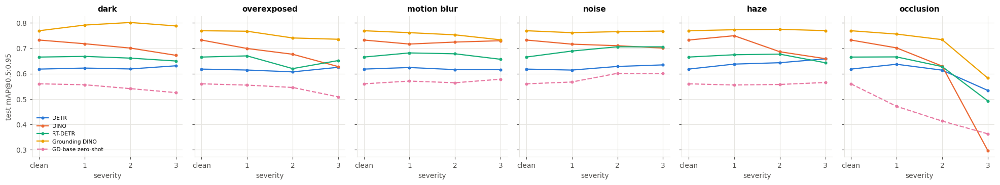

saved -> outputs\figures\fig11_corruption_examples.png


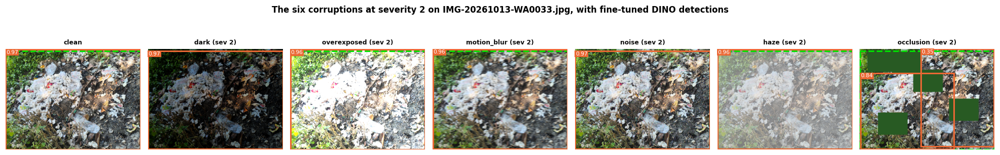

In [24]:
fig, axes = plt.subplots(1, 6, figsize=(18, 3.4), sharey=True)
for ax, c in zip(axes, GE.CORRUPTIONS):
    for k in MODELS + ["GD-base zero-shot"]:
        y = [clean[k]["AP"]] + [ROB[(k, c, s)]["AP"] for s in (1, 2, 3)]
        ax.plot([0, 1, 2, 3], y, "-o", ms=3, color=COL[k], ls="--" if "zero" in k else "-", label=k)
    ax.set_title(c.replace("_", " ")); ax.set_xticks([0, 1, 2, 3], ["clean", "1", "2", "3"]); ax.set_xlabel("severity")
axes[0].set_ylabel("test mAP@0.5:0.95"); axes[0].legend(fontsize=7)
plt.tight_layout(); savefig(fig, "fig10_robustness_corruptions.png"); plt.show()

f = TEST[3]
fig, axes = plt.subplots(1, 7, figsize=(18, 3.2))
m = GT.load_finetuned("dino_s0", "DINO")
for ax, (t, tr) in zip(axes, [("clean", None)] + [(f"{c} (sev 2)", GE.corrupt(c, 2)) for c in GE.CORRUPTIONS]):
    img = TEST_IMGS[f] if tr is None else tr(TEST_IMGS[f])
    p = GE.predict_images(m, {f: img})[f]
    draw_boxes(ax, img, gt=boxes[boxes.file == f][["x1", "y1", "x2", "y2"]].values, pred=p, colour=COL["DINO"], title=t)
del m; torch.cuda.empty_cache()
plt.suptitle(f"The six corruptions at severity 2 on {f}, with fine-tuned DINO detections", fontweight="bold")
plt.tight_layout(); savefig(fig, "fig11_corruption_examples.png"); plt.show()

model                                          DETR  DINO  RT-DETR  \
attribute    value                   n images                        
background   concrete                2         0.38  0.26     0.37   
             container               1         0.86  0.92     0.88   
             dense                   3         1.00  1.00     1.00   
             leaves                  6         0.87  0.87     0.87   
             soil                    5         0.77  0.82     0.80   
             vegetation              3         0.92  0.84     0.92   
composition  food                    1         0.86  0.92     0.88   
             mixed                   9         0.89  0.89     0.91   
             paper                   5         0.91  0.92     0.92   
             plastic                 5         0.60  0.55     0.59   
illumination bright                  6         0.71  0.71     0.70   
             dark                    6         0.80  0.83     0.86   
             medium                  8         0.92  0.88     0.91   
occluded     no                      16        0.86  0.89     0.88   
             yes                     4         0.66  0.53     0.64   
pile_size    large / close-up (>60%) 13        0.92  0.90     0.91   
             medium (15-60%)         6         0.68  0.75     0.76   
             small (<15%)            1         0.40  0.15     0.14   

model                                          Grounding DINO  
attribute    value                   n images                  
background   concrete                2                   0.35  
             container               1                   0.93  
             dense                   3                   1.00  
             leaves                  6                   0.87  
             soil                    5                   0.84  
             vegetation              3                   0.97  
composition  food                    1                   0.93  
             mixed                   9                   0.94  
             paper                   5                   0.92  
             plastic                 5                   0.60  
illumination bright                  6                   0.80  
             dark                    6                   0.78  
             medium                  8                   0.93  
occluded     no                      16                  0.89  
             yes                     4                   0.67  
pile_size    large / close-up (>60%) 13                  0.93  
             medium (15-60%)         6                   0.71  
             small (<15%)            1                   0.63

n images   AP50     AP
attribute    value                                          
pile_size    large / close-up (>60%)        81  0.697  0.615
             medium (15-60%)                28  0.577  0.385
             small (<15%)                    7  0.385  0.172
background   concrete                        5  0.637  0.489
             container                      17  0.728  0.639
             dense                          19  0.927  0.909
             leaves                         20  0.659  0.516
             soil                           28  0.454  0.322
             vegetation                     27  0.615  0.453
composition  food                            5  1.000  0.916
             garden                          2  0.646  0.509
             household                       2  1.000  0.735
             mixed                          58  0.655  0.549
             paper                          20  0.723  0.604
             plastic                        27  0.601  0.438
             rubble                          2  1.000  0.825
occluded     no                             95  0.667  0.542
             yes                            21  0.451  0.388
illumination bright                         39  0.664  0.543
             dark                           39  0.575  0.424
             medium                         38  0.696  0.610

saved -> outputs\figures\fig12_attributes.png


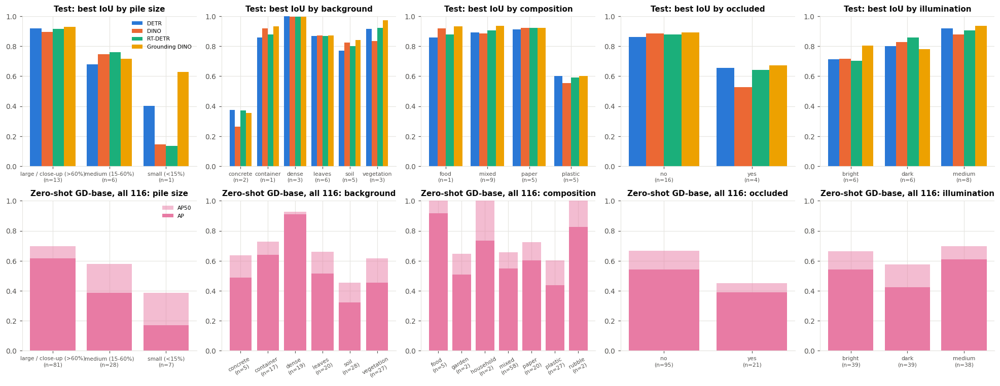

In [25]:
# (b) natural conditions: per-image detection on the test set (3 seeds pooled) and zero-shot GD-base on all 116 photos
meta["occluded"] = meta.occluded.map({0: "no", 1: "yes", "no": "no", "yes": "yes"})
ATTR = ["pile_size", "background", "composition", "occluded", "illumination"]
per = []
for k in MODELS:
    for s in SEEDS:
        _, d = GE.pr_at(FT[f"{TAG[k]}_s{s}"], boxes, 0.3, TEST)
        d["model"], d["seed"] = k, s; per.append(d)
PER = pd.concat(per).merge(meta, on="file")
PER["recall_img"] = PER.tp / (PER.tp + PER.fn)
rows = []
for a in ATTR:
    for v, g in PER.groupby(a):
        for k in MODELS:
            gg = g[g.model == k]
            rows.append({"attribute": a, "value": str(v), "model": k, "n images": gg.file.nunique(), "recall": gg.recall_img.mean(),
                         "max IoU": gg.max_iou.mean(), "FP / image": gg.fp.mean()})
ATT = pd.DataFrame(rows); ATT.to_csv(RES / "attributes_test.csv", index=False)
display(ATT.pivot_table(index=["attribute", "value", "n images"], columns="model", values="max IoU")[MODELS].round(2))

zs = PRE["GD-base | a pile of garbage"]; rows = []
for a in ATTR:
    for v, g in meta.groupby(a):
        fs = g.file.tolist(); m = GE.coco_eval({f: zs[f] for f in fs}, boxes, meta, fs)
        rows.append({"attribute": a, "value": str(v), "n images": len(fs), "AP50": m["AP50"], "AP": m["AP"]})
ATTZ = pd.DataFrame(rows); display(ATTZ.set_index(["attribute", "value"]).round(3)); ATTZ.to_csv(RES / "attributes_zeroshot_all.csv", index=False)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for j, a in enumerate(ATTR):
    t = ATT[ATT.attribute == a].pivot_table(index="value", columns="model", values="max IoU")[MODELS]
    ax = axes[0, j]; x = np.arange(len(t))
    for i, k in enumerate(MODELS):
        ax.bar(x + (i - 1.5) * 0.2, t[k], 0.2, color=COL[k], label=k)
    n = ATT[(ATT.attribute == a) & (ATT.model == "DINO")].set_index("value")["n images"]
    ax.set_xticks(x, [f"{v}\n(n={n[v]})" for v in t.index], fontsize=7); ax.set_ylim(0, 1); ax.set_title(f"Test: best IoU by {a.replace('_', ' ')}")
    z = ATTZ[ATTZ.attribute == a]; ax = axes[1, j]
    ax.bar(range(len(z)), z.AP50, color=COL["GD-base zero-shot"], alpha=0.5, label="AP50"); ax.bar(range(len(z)), z.AP, color=COL["GD-base zero-shot"], label="AP")
    ax.set_xticks(range(len(z)), [f"{v}\n(n={n})" for v, n in zip(z.value, z["n images"])], fontsize=7, rotation=30 if len(z) > 5 else 0); ax.set_ylim(0, 1)
    ax.set_title(f"Zero-shot GD-base, all 116: {a.replace('_', ' ')}")
axes[0, 0].legend(fontsize=7); axes[1, 0].legend(fontsize=7)
plt.tight_layout(); savefig(fig, "fig12_attributes.png"); plt.show()

---
# 10. Qualitative results: successes and failures

saved -> outputs\figures\fig13_qualitative_test.png


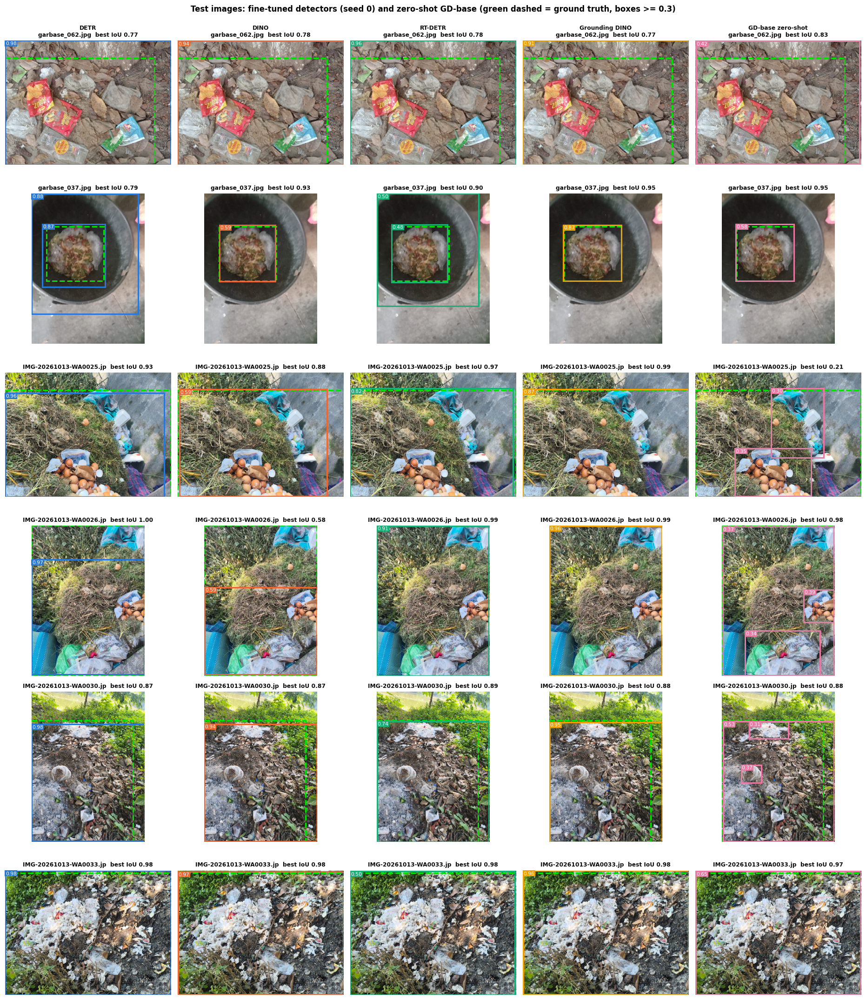

In [26]:
show = ["IMG_20261012_121408.jpg", "garbase_054.jpg", "IMG-20261013-WA0034.jpg", "garbase_062.jpg", "IMG_20261012_121834.jpg", "garbase_037.jpg"]
show = [f for f in show if f in TEST] + [f for f in TEST if f not in show]
show = show[:6]
fig, axes = plt.subplots(len(show), 5, figsize=(17, 3.3 * len(show)))
cols = [(k, FT[f"{TAG[k]}_s0"], COL[k]) for k in MODELS] + [("GD-base zero-shot", PRE["GD-base | a pile of garbage"], COL["GD-base zero-shot"])]
for r, f in enumerate(show):
    gt = boxes[boxes.file == f][["x1", "y1", "x2", "y2"]].values
    for c, (k, p, colr) in enumerate(cols):
        iou = GE.box_iou(p[f][0][p[f][1] >= 0.3], gt).max() if (p[f][1] >= 0.3).any() else 0
        draw_boxes(axes[r, c], TEST_IMGS[f], gt=gt, pred=p[f], colour=colr, title=(f"{k}\n" if r == 0 else "") + f"{f[:22]}  best IoU {iou:.2f}")
plt.tight_layout(rect=(0, 0, 1, 0.985))
plt.suptitle("Test images: fine-tuned detectors (seed 0) and zero-shot GD-base (green dashed = ground truth, boxes >= 0.3)", fontweight="bold", y=0.997)
savefig(fig, "fig13_qualitative_test.png"); plt.show()

case,correct,false positive,inaccurate box (IoU<0.5),missed pile
model,,,,
DETR,15,3,1,1
DINO,18,1,0,1
Grounding DINO,18,0,0,2
RT-DETR,17,1,0,2


saved -> outputs\figures\fig14_failure_cases.png


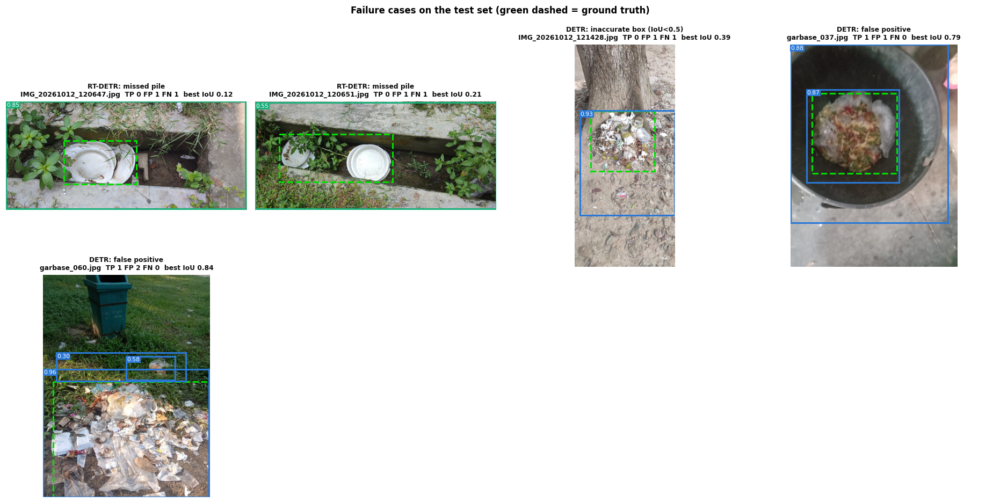

In [27]:
# automatically selected failure cases: missed piles, false positives and inaccurate boxes (seed 0, threshold 0.3)
rows = []
for k in MODELS:
    _, d = GE.pr_at(FT[f"{TAG[k]}_s0"], boxes, 0.3, TEST); d["model"] = k; rows.append(d)
F = pd.concat(rows)
F["case"] = np.where(F.fn > 0, np.where(F.max_iou > 0.3, "inaccurate box (IoU<0.5)", "missed pile"), np.where(F.fp > 0, "false positive", "correct"))
display(F.pivot_table(index="model", columns="case", values="file", aggfunc="count").fillna(0).astype(int))
F.to_csv(RES / "per_image_outcomes_seed0.csv", index=False)
bad = F[F.case != "correct"].sort_values(["max_iou"]).drop_duplicates("file").head(8)
fig, axes = plt.subplots(2, 4, figsize=(17, 8.5))
for ax, r in zip(axes.ravel(), bad.itertuples()):
    gt = boxes[boxes.file == r.file][["x1", "y1", "x2", "y2"]].values
    draw_boxes(ax, TEST_IMGS[r.file], gt=gt, pred=FT[f"{TAG[r.model]}_s0"][r.file], colour=COL[r.model],
               title=f"{r.model}: {r.case}\n{r.file[:24]}  TP {r.tp} FP {r.fp} FN {r.fn}  best IoU {r.max_iou:.2f}")
for ax in axes.ravel()[len(bad):]:
    ax.axis("off")
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.suptitle("Failure cases on the test set (green dashed = ground truth)", fontweight="bold", y=0.995)
savefig(fig, "fig14_failure_cases.png"); plt.show()

---
# 11. Grounding DINO: text prompts and the interactive interface

## 11.1 Prompt wording

Because zero-shot Grounding DINO never trains on the RU photos, all 116 images can be used to compare prompts. The
three prompts from the assignment are compared with short nouns (*garbage, trash, litter, waste*), longer descriptions
and type-specific prompts, for the tiny and the base model. The fine-tuned tiny model was trained with *"a pile of
garbage"*. It is also tested with the other prompts on the test set, to see how much fine-tuning ties it to that
wording.

In [28]:
PROMPTS = ["a pile of garbage", "a pile of plastic waste", "garbage dumped beside a campus road", "garbage", "trash", "litter",
           "waste", "rubbish heap", "pile of trash", "dumped waste on the ground", "a pile of paper waste", "food waste",
           "plastic bags", "garbage . trash . litter"]
rows = []
for tag, ck in [("GD-tiny", "IDEA-Research/grounding-dino-tiny"), ("GD-base", "IDEA-Research/grounding-dino-base")]:
    m = GM.GroundingDINO(ckpt=ck)
    for pr in PROMPTS:
        def run(pr=pr):
            m.set_prompt(pr); return GE.predict_images(m, ALL_IMGS)
        p = cached(f"zeroshot_{tag}_{pr.replace(' ', '_')}", run)
        rows.append({"model": f"{tag} zero-shot", "prompt": pr, **evaluate(p, ALL)})
        if tag == "GD-base":
            for comp in ["plastic", "paper", "mixed", "food"]:
                fs = meta[meta.composition == comp].file.tolist()
                rows.append({"model": f"{tag} zero-shot | {comp} only", "prompt": pr, **GE.coco_eval({f: p[f] for f in fs}, boxes, meta, fs)})
    del m; torch.cuda.empty_cache()
mft = GT.load_finetuned("gdino_s0", "Grounding DINO")
for pr in PROMPTS:
    def run(pr=pr):
        mft.set_prompt(pr); return GE.predict_images(mft, TEST_IMGS)
    p = cached(f"gdino_s0_prompt_{pr.replace(' ', '_')}", run)
    rows.append({"model": "GD-tiny fine-tuned (test)", "prompt": pr, **evaluate(p, TEST)})
    m0 = PRE.get(f"GD-tiny | {pr}") or cached(f"zeroshot_GD-tiny_{pr.replace(' ', '_')}", lambda: None)
    rows.append({"model": "GD-tiny zero-shot (test)", "prompt": pr, **evaluate(m0, TEST)})
mft.set_prompt("a pile of garbage")
PROMPT_DF = pd.DataFrame(rows); PROMPT_DF.to_csv(RES / "prompt_analysis.csv", index=False)
pt = PROMPT_DF.pivot_table(index="prompt", columns="model", values="AP").loc[PROMPTS]
display(pt.round(3))

model,GD-base zero-shot,GD-base zero-shot | food only,GD-base zero-shot | mixed only,GD-base zero-shot | paper only,GD-base zero-shot | plastic only,GD-tiny fine-tuned (test),GD-tiny zero-shot,GD-tiny zero-shot (test)
prompt,,,,,,,,
a pile of garbage,0.513,0.916,0.549,0.604,0.438,0.769,0.520,0.583
a pile of plastic waste,0.472,0.753,0.541,0.533,0.315,0.798,0.442,0.492
garbage dumped beside a campus road,0.539,0.747,0.612,0.573,0.373,0.776,0.520,0.503
garbage,0.566,0.916,0.626,0.687,0.320,0.792,0.592,0.588
trash,0.558,0.853,0.620,0.613,0.364,0.786,0.191,0.097
litter,0.474,0.916,0.565,0.568,0.204,0.794,0.447,0.382
waste,0.576,0.916,0.626,0.709,0.357,0.806,0.585,0.594
rubbish heap,0.674,0.861,0.697,0.783,0.575,0.761,0.666,0.698
pile of trash,0.564,0.916,0.591,0.650,0.473,0.761,0.589,0.631


saved -> outputs\figures\fig15_prompt_analysis.png


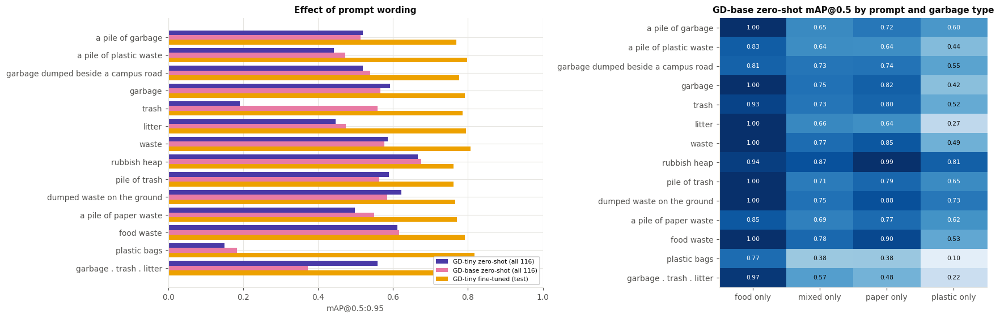

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]; y = np.arange(len(PROMPTS))
for i, (mname, c) in enumerate([("GD-tiny zero-shot", COL["GD-tiny zero-shot"]), ("GD-base zero-shot", COL["GD-base zero-shot"]),
                                ("GD-tiny fine-tuned (test)", COL["Grounding DINO"])]):
    ax.barh(y + (i - 1) * 0.27, pt[mname], 0.27, color=c, label=mname + (" (all 116)" if "zero" in mname else ""))
ax.set_yticks(y, PROMPTS); ax.invert_yaxis(); ax.set_xlabel("mAP@0.5:0.95"); ax.set_title("Effect of prompt wording"); ax.set_xlim(0, 1.32); ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.legend(fontsize=7, loc="upper right", frameon=True, framealpha=1)
ax = axes[1]
hm = PROMPT_DF[PROMPT_DF.model.str.contains("only")].pivot_table(index="prompt", columns="model", values="AP50").loc[PROMPTS]
hm.columns = [c.split("| ")[1] for c in hm.columns]
im = ax.imshow(hm.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(hm.shape[1]), hm.columns); ax.set_yticks(range(len(PROMPTS)), PROMPTS); ax.grid(False)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f"{hm.values[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if hm.values[i, j] > 0.6 else INK)
ax.set_title("GD-base zero-shot mAP@0.5 by prompt and garbage type")
plt.tight_layout(); savefig(fig, "fig15_prompt_analysis.png"); plt.show()

## 11.2 Interactive interface

`app.py` is a Gradio app. The user uploads a campus photo, types a prompt and picks a model (GD-base zero-shot, GD-tiny
zero-shot or the fine-tuned GD-tiny) and a confidence threshold. The app draws every matching pile with its score and
lists the boxes. Start it with `python app.py` and open http://127.0.0.1:7860. The cell below starts the app, takes a
screenshot with a headless browser, and runs the same function the button calls on one photo with four prompts.

In [30]:
%%writefile app.py
"""Text-prompt garbage detection on RU-campus photos with Grounding DINO.  Run:  python app.py  (http://127.0.0.1:7860)"""
import os
import numpy as np
import gradio as gr
import torch
from PIL import Image, ImageOps, ImageDraw, ImageFont
from pathlib import Path
from gbg_data import letterbox

ROOT = Path(__file__).resolve().parent
FT = ROOT / "outputs" / "runs" / "gdino_s0" / "best.pt"
CHOICES = {"Grounding DINO base (zero-shot)": ("IDEA-Research/grounding-dino-base", None),
           "Grounding DINO tiny (zero-shot)": ("IDEA-Research/grounding-dino-tiny", None),
           "Grounding DINO tiny (fine-tuned on RU campus)": ("IDEA-Research/grounding-dino-tiny", FT)}
_MODELS = {}


def get_model(choice):
    if choice not in _MODELS:
        from gbg_models import GroundingDINO
        ckpt, weights = CHOICES[choice]
        m = GroundingDINO(ckpt=ckpt)
        if weights is not None and Path(weights).exists():
            m.load_state_dict(torch.load(weights, map_location="cpu", weights_only=False))
        m.eval()
        _MODELS[choice] = m
    return _MODELS[choice]


def draw(img, boxes, scores, colour=(255, 40, 40)):
    im = img.copy()
    d = ImageDraw.Draw(im)
    W, H = im.size
    lw = max(3, round(max(W, H) / 250))
    try:
        font = ImageFont.truetype("arial.ttf", max(16, round(max(W, H) / 45)))
    except OSError:
        font = ImageFont.load_default()
    for b, s in zip(boxes, scores):
        x1, y1, x2, y2 = b[0] * W, b[1] * H, b[2] * W, b[3] * H
        d.rectangle([x1, y1, x2, y2], outline=colour, width=lw)
        t = f"{s:.2f}"
        tw, th = d.textbbox((0, 0), t, font=font)[2:]
        d.rectangle([x1, max(0, y1 - th - 6), x1 + tw + 8, max(th + 6, y1)], fill=colour)
        d.text((x1 + 4, max(0, y1 - th - 4)), t, fill="white", font=font)
    return im


def detect(image, prompt, choice, threshold, model=None):
    from gbg_eval import nms
    if image is None or not prompt.strip():
        return None, "Upload an image and type a prompt."
    img = ImageOps.exif_transpose(image).convert("RGB")
    img.thumbnail((1280, 1280))
    m = model or get_model(choice)
    m.set_prompt(prompt)
    lb, v = letterbox(np.asarray(img))
    boxes, scores = m.predict(torch.from_numpy(lb[None]).permute(0, 3, 1, 2).contiguous(), [v])[0]
    boxes, scores = boxes.cpu().numpy(), scores.cpu().numpy()
    keep = scores >= threshold
    boxes, scores = boxes[keep], scores[keep]
    if len(boxes):
        k = nms(boxes, scores, 0.5)
        boxes, scores = boxes[k], scores[k]
    rows = "\n".join(f"| {i + 1} | {s:.3f} | {b[0]:.2f}, {b[1]:.2f}, {b[2]:.2f}, {b[3]:.2f} |" for i, (b, s) in enumerate(zip(boxes, scores)))
    md = (f"**Prompt:** `{m.prompt}` — **{len(boxes)} garbage pile(s)** with confidence ≥ {threshold:.2f}\n\n"
          + ("| # | confidence | box (x1, y1, x2, y2), normalised |\n|---|---|---|\n" + rows if len(boxes) else ""))
    return draw(img, boxes, scores), md


def build_demo():
    ex_dir = ROOT / "cache" / "img"
    examples = [[str(ex_dir / f), p] for f, p in [
        ("IMG_20261012_121408.jpg", "a pile of garbage"),
        ("garbase_054.jpg", "garbage dumped beside a campus road"),
        ("garbase_062.jpg", "a pile of plastic waste"),
        ("IMG-20261013-WA0034.jpg", "food waste"),
        ("IMG_20261012_121834.jpg", "a pile of paper waste")] if (ex_dir / f).exists()]
    with gr.Blocks(title="RU campus garbage detection") as demo:
        gr.Markdown("# Text-prompt garbage detection — Rajshahi University campus\n"
                    "Upload a campus photo, describe the garbage you are looking for, and Grounding DINO draws a box "
                    "around every matching pile with its confidence score.")
        with gr.Row():
            with gr.Column():
                image = gr.Image(type="pil", label="Campus image", height=380)
                prompt = gr.Textbox(label="Prompt", value="a pile of garbage")
                choice = gr.Dropdown(list(CHOICES), value=list(CHOICES)[0], label="Model")
                thr = gr.Slider(0.05, 0.9, value=0.3, step=0.05, label="Confidence threshold")
                btn = gr.Button("Detect garbage", variant="primary")
                gr.Examples(examples, [image, prompt])
            with gr.Column():
                out = gr.Image(label="Detections", height=420)
                txt = gr.Markdown()
        btn.click(detect, [image, prompt, choice, thr], [out, txt])
    return demo


if __name__ == "__main__":
    build_demo().launch(server_name="127.0.0.1", server_port=int(os.environ.get("PORT", 7860)))

Overwriting app.py


UI reachable: True


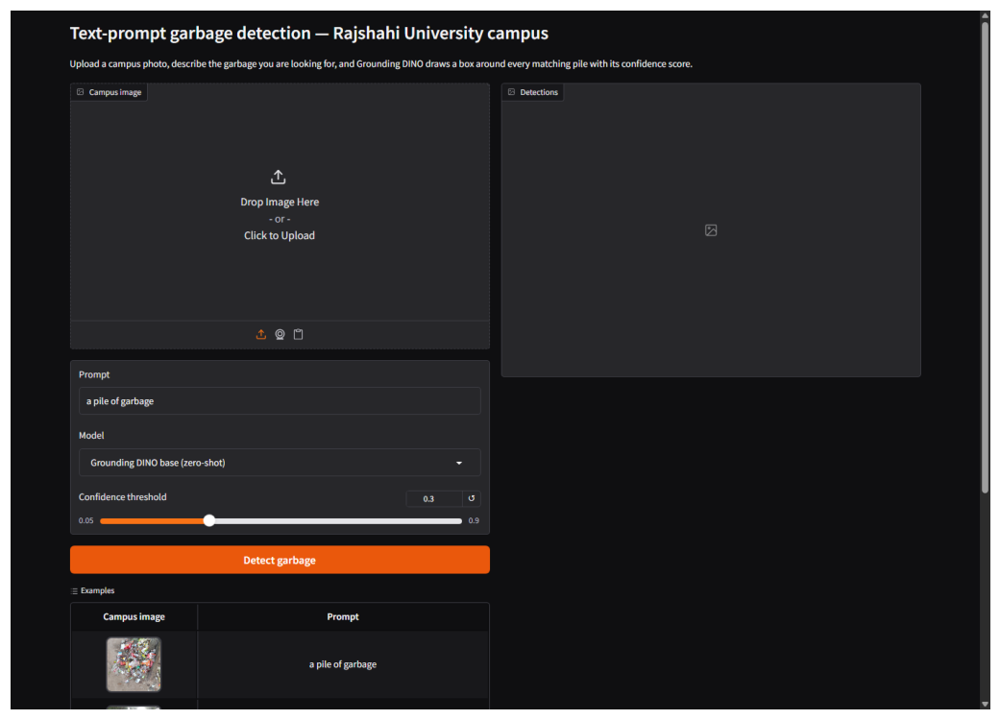

saved -> outputs\figures\fig17_ui_prompts.png


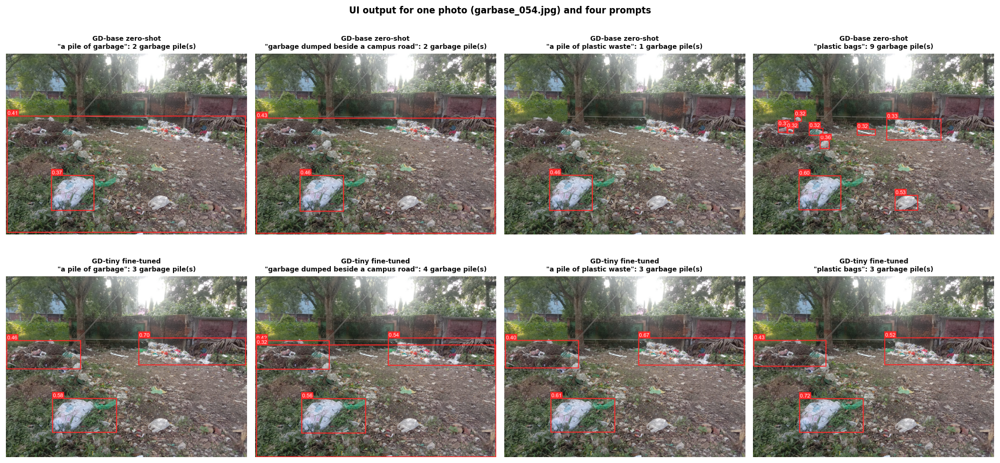

In [31]:
import urllib.request
proc = subprocess.Popen([sys.executable, "app.py"], cwd=ROOT, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, env={**os.environ, "PORT": "7861"})
ok = False
for _ in range(120):
    try:
        ok = urllib.request.urlopen("http://127.0.0.1:7861", timeout=2).status == 200; break
    except Exception:
        time.sleep(1)
print("UI reachable:", ok)
edge = next((p for p in [r"C:\Program Files (x86)\Microsoft\Edge\Application\msedge.exe", r"C:\Program Files\Microsoft\Edge\Application\msedge.exe"] if Path(p).exists()), None)
if ok and edge:
    subprocess.run([edge, "--headless=new", "--disable-gpu", f"--screenshot={FIG / 'fig16_ui_screenshot.png'}", "--window-size=1400,1000",
                    "--virtual-time-budget=15000", "http://127.0.0.1:7861"], timeout=120)
proc.terminate()
if (FIG / "fig16_ui_screenshot.png").exists():
    plt.figure(figsize=(12, 8.6)); plt.imshow(Image.open(FIG / "fig16_ui_screenshot.png")); plt.axis("off"); plt.show()

import app
gd_base = GM.GroundingDINO(ckpt="IDEA-Research/grounding-dino-base")
f = "garbase_054.jpg" if "garbase_054.jpg" in ALL else ALL[0]
img = Image.open(GD.CACHE / f)
ui_prompts = ["a pile of garbage", "garbage dumped beside a campus road", "a pile of plastic waste", "plastic bags"]
fig, axes = plt.subplots(2, 4, figsize=(17, 8.5))
for j, pr in enumerate(ui_prompts):
    for i, (mname, mm) in enumerate([("GD-base zero-shot", gd_base), ("GD-tiny fine-tuned", mft)]):
        out, txt = app.detect(img, pr, None, 0.3, model=mm)
        axes[i, j].imshow(out); axes[i, j].axis("off")
        axes[i, j].set_title(f"{mname}\n\"{pr}\": {txt.split('**')[3]}", fontsize=8)
plt.suptitle(f"UI output for one photo ({f}) and four prompts", fontweight="bold")
plt.tight_layout(); savefig(fig, "fig17_ui_prompts.png"); plt.show()
del gd_base; torch.cuda.empty_cache()

---
# 12. Summary

In [32]:
S = pd.DataFrame({k: {"mAP@0.5": agg.loc[k, ("AP50", "mean")], "mAP@0.5:0.95": agg.loc[k, ("AP", "mean")],
                      "precision@0.3": agg.loc[k, ("precision", "mean")], "recall@0.3": agg.loc[k, ("recall", "mean")],
                      "robust mAP@0.5 (6 corruptions)": summ.loc[k, "mean (all corruptions)"],
                      "latency (ms)": SPEED[k]["latency_ms"], "FPS": SPEED[k]["FPS_bs1"], "params (M)": SPEED[k]["params (M)"],
                      "train time (min)": COST.loc[k, ("train time (min)", "mean")]} for k in MODELS}).T
z = PRE_DF.loc[("GD-base | a pile of garbage", "test")]
S.loc["GD-base zero-shot"] = [z.AP50, z.AP, z.precision, z.recall, summ.loc["GD-base zero-shot", "mean (all corruptions)"],
                              SPEED["GD-base zero-shot"]["latency_ms"], SPEED["GD-base zero-shot"]["FPS_bs1"], SPEED["GD-base zero-shot"]["params (M)"], 0]
display(S.round(3)); S.round(4).to_csv(RES / "summary.csv")
json.dump({"summary": S.round(4).reset_index().to_dict("records")}, open(RES / "summary.json", "w"), indent=1)
print("figures:", len(list(FIG.glob("*.png"))), "| result files:", len(list(RES.glob("*"))))

,mAP@0.5,mAP@0.5:0.95,precision@0.3,recall@0.3,robust mAP@0.5 (6 corruptions),latency (ms),FPS,params (M),train time (min)
DETR,0.860,0.650,0.741,0.900,0.843,24.168,41.376,41.502,2.89
DINO,0.891,0.684,0.873,0.917,0.890,67.057,14.913,46.824,9.73
RT-DETR,0.853,0.661,0.792,0.933,0.837,29.760,33.602,42.729,5.31
Grounding DINO,0.965,0.783,0.950,0.933,0.930,81.786,12.227,172.249,12.88
GD-base zero-shot,0.652,0.560,0.600,0.900,0.657,95.034,10.523,232.313,0.00


figures: 17 | result files: 19


## 12.1 Main findings

| model | mAP@0.5 | mAP@0.5:0.95 | precision / recall @0.3 | robust mAP@0.5 | latency | FPS | params |
|---|---|---|---|---|---|---|---|
| DETR | 0.860 ± 0.005 | 0.650 ± 0.034 | 0.74 / 0.90 | 0.843 | **24 ms** | **41** | 41.5 M |
| DINO | 0.891 ± 0.037 | 0.684 ± 0.045 | 0.87 / 0.92 | 0.890 | 67 ms | 15 | 46.8 M |
| RT-DETR | 0.853 ± 0.067 | 0.661 ± 0.063 | 0.79 / 0.93 | 0.837 | 30 ms | 34 | 42.7 M |
| **Grounding DINO** (fine-tuned) | **0.965 ± 0.028** | **0.783 ± 0.021** | **0.95 / 0.93** | **0.930** | 82 ms | 12 | 172 M |
| Grounding DINO base, zero-shot | 0.652 | 0.560 | 0.60 / 0.90 | 0.657 | 95 ms | 11 | 232 M |

(mean ± std over 3 training seeds on the 20 held-out test images; robust = mean mAP@0.5 over 6 corruptions × 3 severities.)

* **Fine-tuning is essential.** Used class-agnostically, the COCO-pretrained DETR, DINO and RT-DETR reach only 0.015–0.021
  mAP@0.5. They do not see a pile at all; they fire on individual items and call them *bottle*, *bowl*, *banana* or
  *teddy bear*. After fine-tuning on 77 photos they reach 0.85–0.97. Grounding DINO is the exception: zero-shot it already
  reaches 0.716 (tiny) and 0.652 (base) with *"a pile of garbage"*, because it understands the phrase. Fine-tuning still adds
  +0.25 mAP@0.5, mainly by learning *this dataset's* idea of where one pile ends (zero-shot it often splits a pile into items).
* **Grounding DINO fine-tuned is the most accurate and the most robust** model, with the lowest seed variance, but also
  the largest (172 M parameters) and slowest (12 FPS). Its pre-training on image–text grounding data transfers best to a
  vague, texture-defined class like *piled garbage*.
* **DINO** is second (0.891). It is the most precise of the three closed-set models, but its pure-PyTorch deformable
  attention makes it the slowest of them (15 FPS) and the most memory-hungry to train (11 GB).
* **RT-DETR and DETR** are the fast options (34 and 41 FPS at batch 1, 98 and 133 FPS at batch 8) with about 0.85 mAP@0.5.
  RT-DETR has the highest recall but also the largest seed-to-seed variance (±0.067). On a 20-image test set the
  differences between DETR, DINO and RT-DETR are within one standard deviation, so they should be read as *similar*.
  Only Grounding DINO's lead is larger than the spread.
* **DETR converged within 60 epochs here**, contrary to its reputation (its validation mAP rises slowly over the first
  ~20 epochs, Fig. 5). With a single large object per image and a strong pretrained decoder, its slow bipartite-matching
  convergence is much less of a problem than on COCO. Training it for 150 epochs raised test mAP@0.5:0.95 further (0.618 → 0.666).

## 12.2 Training configurations (§8, single seed, compare with care)

* Input **800 px** helped RT-DETR (0.665 → 0.692) at no measurable latency cost. At batch 1 on this GPU all three
  resolutions run in 27–31 ms, because the network is limited by kernel-launch overhead, not computation.
* **DINO for 12 epochs** already reaches 0.670 (vs 0.732 at 60 epochs) in a fifth of the time, which supports DINO's fast-convergence claim.
* **Freezing Grounding DINO's Swin backbone** cut the trainable parameters by 43 % (63.4 M → 35.8 M) and 2.5 GB of training memory with no
  loss (0.811 vs 0.769). With only 77 training images, adapting just the fusion and decoder layers is enough.
* **Augmentation** did not improve clean test accuracy for RT-DETR (0.678 without vs 0.665 with). With 20 test images
  this is within noise, and the corruption benchmark (§9) shows all fine-tuned models stay within a few points of their
  clean score under lighting, blur, noise and haze changes.

## 12.3 Robustness and difficult conditions (§9, §10)

* Lighting, blur, noise and haze barely affect the fine-tuned models: averaged over the three severities, no model loses more than 0.064 mAP@0.5:0.95 (DINO, overexposure), and Grounding DINO even scores slightly higher on darkened images.
* **Occlusion is the hardest condition** for every model. At severity 3 DINO drops 0.73 → 0.30, RT-DETR 0.67 → 0.49 and
  Grounding DINO 0.77 → 0.58. DINO's collapse suggests it relies on seeing the pile's complete outline.
* **Small, distant piles** and **piles on concrete** are the weakest natural cases (best IoU 0.14–0.63 for the single small
  test pile; 0.26–0.37 on concrete). The same holds for zero-shot GD-base on all 116 photos (AP 0.17 for small piles vs 0.61
  for large ones). **Plastic-dominated** piles score lowest by composition, because thin bags against grass or leaves have
  weak boundaries. Dense, frame-filling dumps are the easiest (≈ 0.99 IoU).
* Typical failures (Fig. 14): white plates in a drain that RT-DETR boxes as the whole scene, a pile at a tree base whose
  extent DETR overestimates, and a dustbin or a lone bag next to the pile reported as an extra pile (false positive).

## 12.4 Text prompts (§11)

* Zero-shot results depend strongly on the wording. *"rubbish heap"* is best (GD-base AP 0.674), *"plastic bags"* worst
  (0.183), and *"trash"* fails for GD-tiny (0.191) while working for GD-base (0.558). Type-specific prompts do not help on
  their own type: *"a pile of plastic waste"* scores lower on plastic piles than *"rubbish heap"*.
* After fine-tuning, Grounding DINO becomes almost **insensitive to the prompt** (test AP 0.761–0.817 for all 14 prompts,
  including *"plastic bags"*). It has learned the visual concept and largely stopped reading the text, so a fine-tuned
  model should not be expected to follow new, more specific prompts.

## 12.5 Limitations

* The dataset is small (116 photos, 20 test images). Seed-to-seed standard deviations of 0.02–0.07 mAP are as large as
  several of the differences between models, so all model rankings except Grounding DINO's lead are uncertain.
* The bounding boxes were drawn by the author on a reference grid. The extent of a scattered pile is partly a judgement
  call, which mainly limits mAP@0.5:0.95 (the strict IoU thresholds).
* Speed is measured on one desktop GPU. DINO uses the pure-PyTorch deformable attention, so its latency would be lower
  with the compiled CUDA operator.
